# Chapter 8: Advanced Eigenstate Algorithms: The Rodeo Algorithm and Filtering

*This chapter presents algorithms that prepare and extract specific eigenstates of a Hamiltonian by filtering, together with a way of supplying them with the input they need. We first introduce resolution refinement, which lifts an eigenstate of a coarse model space into a finer one with a prolongation operator and follows a gapped adiabatic path between the two Hamiltonians, delivering a state with a large overlap with the target. We then derive the rodeo algorithm, a measurement-driven stochastic method in which one ancilla qubit, controlled time evolutions of random duration and post-selection suppress all components outside a target energy window exponentially fast, and which also serves as a spectrometer. The two are combined end to end on the pairing model and compared, as state-preparation methods, with the variational eigensolver and with quantum phase estimation in terms of resource requirements and precision. The same pipeline is then applied to the Lipkin, Heisenberg and Hubbard Hamiltonians. The chapter closes with a gate-level compilation of every stage, including Trotterized evolution, and a depth budget that is held against present and forthcoming hardware as an overview of the bottlenecks of quantum computing for many-body problems. Other spectral filtering techniques are mentioned as alternative approaches.*


<!-- Macro definitions for MathJax, mirroring book.tex -->
$$
\newcommand{\bm}[1]{\boldsymbol{#1}}
\newcommand{\matr}[1]{\boldsymbol{#1}}
\newcommand{\bfv}[1]{\boldsymbol{#1}}
\renewcommand{\vec}[1]{\boldsymbol{#1}}
\newcommand{\uvec}[1]{\boldsymbol{\hat{#1}}}
\newcommand{\op}[1]{\widehat{#1}}
\newcommand{\Op}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\OP}[1]{\boldsymbol{\widehat{#1}}}
\newcommand{\Det}[1]{|\boldsymbol{#1}|}
\newcommand{\bigO}{\mathcal{O}}
\newcommand{\var}{\mathrm{Var}}
\newcommand{\cov}{\mathrm{Cov}}
\newcommand{\real}[1]{\mathrm{Re}\left\{#1\right\}}
\newcommand{\ud}[1]{d#1}
\newcommand{\udd}[1]{d^2#1}
\newcommand{\mean}[1]{\langle #1 \rangle}
\newcommand{\overlap}[2]{\langle #1 | #2 \rangle}
\newcommand{\bracket}[3]{\langle #1 | #2 | #3 \rangle}
\newcommand{\projection}[2]{| #1 \rangle \langle #2 |}
\newcommand{\brab}[1]{\big\langle #1 \big|}
\newcommand{\ketb}[1]{\big| #1 \big\rangle}
\newcommand{\bket}[1]{\vert #1\rangle}
\newcommand{\bbra}[1]{\langle #1\vert}
\newcommand{\ketbra}[2]{\vert #1\rangle\langle #2\vert}
\newcommand{\braket}[2]{\langle #1\vert #2\rangle}
$$

In [1]:
# Put every BookPrograms/chapter*/ and BookPrograms/common/ on sys.path
import sys, pathlib
root = pathlib.Path.cwd().resolve()
while not (root / 'BookPrograms').is_dir() and root.parent != root:
    root = root.parent
sys.path[:0] = [str(p) for p in (root / 'BookPrograms').iterdir() if p.is_dir()]
import numpy as np


## Introduction

The last two chapters ended on the same sentence, read from opposite
sides. Phase estimation, Chapter 6, returns an eigenvalue to
any precision *provided* it is handed a state with a large overlap
with the eigenstate it is asked about, and is silent about where that
state comes from. The variational eigensolver, Chapter 7,
produces a state rather than assuming one, but returns an upper bound
whose quality is a property of the ansatz, and no feature of the output
says how good it is. Section *Phase estimation and VQE weighed against each other* concluded that the
difficulty of the many-body problem is conserved: one method hides it in
state preparation and circuit depth, the other in ansatz design and
measurement count. This chapter is about a third family of algorithms,
the *projective spectral filters*, and about a way of supplying them
with the input they need.

A filter is an operation that multiplies the component of a state along
the eigenvector $\vert E_j\rangle$ by a factor $F(E_j)$ that is close to
one in a window around a chosen energy and small outside it. Applied to
$\vert\psi\rangle=\sum_jc_j\vert E_j\rangle$ and followed by
normalization, it returns a state that is closer to the eigenstate in
the window. Phase estimation is a filter of this kind, as
Section *The state you start from* showed when it collapsed the system register by
reading the control register; filters built from polynomials of
$\hat{H}$ by quantum signal processing [LinTong2020,Dong2022] and
projection by measurement [Stetcu2023] are others. The one this
chapter develops in detail is the *rodeo algorithm*
[Choi2021,Qian2024], which uses a single ancilla qubit, measured and
reused, and controlled time evolutions of random duration. Its filter
factor is a product of cosines, off-resonant components are suppressed by
a factor of two per cycle on average, and the error of the prepared state
therefore falls *exponentially* with the number of cycles. The name
is apt: every cycle gives the state a shake, and only the eigenstate at
the chosen energy stays on.

All filters share one limitation, and it is the one we met for phase
estimation. A filter cannot create weight that is not there. If the
input has squared overlap $p=\vert c_0\vert^2$ with the target, the filter
succeeds with probability $p$, the expected cost grows as $1/p$, and for
an uninformed input $p$ falls exponentially with the number of particles
[Lee2023]. The exponential convergence is real, and it begins only
once somebody has supplied a good input. The first half of the chapter is
therefore not about filtering at all. It introduces *resolution
refinement* [Bogner2026], a state-preparation method that bootstraps
an eigenstate from a coarse model space, where it is cheap to prepare, to
a fine one, by lifting it with a *prolongation* operator and
following an adiabatic path between the two Hamiltonians. Because coarse
and fine Hamiltonians describe the same low-energy physics, the path
stays gapped, and the output has an overlap close to one. It also has a
slow tail: the last percent of overlap costs as much adiabatic time as
the first ninety-nine. That is exactly the profile a filter wants, and
the two methods are complementary in a precise sense. Refinement
supplies the large $p$ that the rodeo algorithm requires; the rodeo
algorithm removes, exponentially fast, the tail that refinement leaves
behind.

The order of the chapter follows this logic. Section *Resolution refinement*
develops resolution refinement and runs it on the pairing model of
Section *The pairing model*, refined from two single-particle levels to
four. Section *The rodeo algorithm* derives the rodeo algorithm from its
one-ancilla circuit, works through a one-qubit example by hand, and
establishes the convergence criterion. Section *Refinement and rodeo together: the pairing model end to end* puts
the two together, end to end, on the pairing Hamiltonian with four
particles on four levels, eight qubits in the Jordan--Wigner encoding of
Section *The pairing model: one qubit per orbital or per level*, where every stage can be checked against
exact diagonalization. Section *The pairing model three ways: rodeo, phase estimation and VQE* sets the result
against the variational calculations of Chapter 7 and the
phase-estimation results of Chapter 6 for the same
Hamiltonian, comparing the three as state-preparation methods at equal
cost. Section *The other three Hamiltonians* carries the pipeline over to the
other three Hamiltonians of the book, the Lipkin model, the Heisenberg
ring and the Hubbard ring, each with the resolution hierarchy that suits
it, and to a genuine two-stage lattice refinement. The chapter closes, in
Section *Circuits, depth and the bottlenecks of quantum computing*, with what is perhaps its most broadly
useful part: every stage is compiled to rotations and CNOT gates, the
product-formula errors are put back in, the gates are counted, and the
count is held against what quantum hardware can execute. The resulting
budget is an overview, on one fully controlled example, of the
bottlenecks of quantum computing for many-body physics: overlap,
coherent depth, Trotter error, encoding, optimization, and noise. The
programs are in `BookPrograms/chapter8/`, and every number quoted
below is printed by one of them.


## Resolution refinement

### The idea

Every calculation in this book has a resolution. For the pairing model
it is the number $k$ of single-particle levels; for a lattice model it
is the lattice spacing; for a nucleus it is the size of the harmonic
oscillator basis; for a molecule the size of the orbital basis. The
resolution sets the number of qubits, $2k$ for $k$ doubly degenerate
levels in the Jordan--Wigner encoding, and with it the cost of every
gate sequence. It does *not* set the physics. A well-constructed
low-resolution Hamiltonian $\hat{H}_{\mathrm{low}}$ has the same
low-lying states as the high-resolution $\hat{H}_{\mathrm{high}}$, only
described more coarsely; this is the content of effective field theory
and of the renormalization group, and classical numerical analysis has
exploited it for half a century in multigrid methods, where the solution
of a differential equation on a coarse grid is interpolated to a fine
grid and used there as the starting point of a short relaxation.
Resolution refinement [Bogner2026] is the quantum version of the
multigrid idea, and it has three steps:

1. *prepare* an eigenstate $\vert\psi_{\mathrm{low}}\rangle$ of
   $\hat{H}_{\mathrm{low}}$ on a small register, by any method; the register
   is small, so a variational circuit, phase estimation, or even a
   classical calculation followed by state loading are all affordable;
2. *prolong* it into the large register,
   $\vert\Phi_0\rangle=\hat{P}\vert\psi_{\mathrm{low}}\rangle$, with an
   isometry $\hat{P}$ that is cheap to implement;
3. *refine* it by evolving adiabatically from a Hamiltonian of
   which $\vert\Phi_0\rangle$ is an eigenstate to $\hat{H}_{\mathrm{high}}$.

The third step is adiabatic state preparation, which
Section *The ansatz and where it comes from* met as the ancestor of QAOA, and the reader
may ask what has been gained, since adiabatic preparation has a
well-known cost: the evolution time grows as the inverse square of the
smallest gap along the path [Albash2018], and nothing prevents the
gap between an arbitrary starting Hamiltonian and the target from
closing. What has been gained is the path. Coarse and fine Hamiltonians
share their low-energy spectrum, so the interpolation between them does
not pass through a rearrangement of the ground state; the gap stays
open, of the order of the physical gap, and the required time grows
only as its inverse. The steps can also be chained, from $k$ to $2k$ to
$4k$, each stage starting from an overlap that is already large.

### The prolongation operator

The prolongation $\hat{P}$ maps the coarse $N$-particle space into the
fine one. It is an isometry, $\hat{P}^\dagger\hat{P}=\mathbb{1}$, while
$\hat{P}\hat{P}^\dagger$ is the projector onto the image of the coarse
space inside the fine space, and $\hat{P}^\dagger$ annihilates everything
outside that image. The most general form we need acts on the creation
operators,

$$
\hat{P}:\quad a^\dagger_c\;\longmapsto\;\sum_f W_{fc}\,a^\dagger_f,
\qquad \sum_f W^*_{fc}W_{fc'}=\delta_{cc'},\tag{8.1}
$$

where $c$ labels coarse and $f$ fine single-particle states. A coarse
Slater determinant with occupied states $C=\{c_1<\dots<c_N\}$ is then
mapped, by expanding the product of the $N$ sums and using the
anticommutation relations, to

$$
\hat{P}\,a^\dagger_{c_1}\cdots a^\dagger_{c_N}\vert 0\rangle
=\sum_{F=\{f_1<\dots<f_N\}}\det\big(W_{FC}\big)\,
a^\dagger_{f_1}\cdots a^\dagger_{f_N}\vert 0\rangle ,\tag{8.2}
$$

with $W_{FC}$ the $N\times N$ submatrix of $W$ with rows $F$ and columns
$C$. This is the formula behind the method `orbital` of `Prolongation` in
`refinement.py`. Two special cases cover everything in this
chapter.

*Basis refinement.* When the fine basis contains the coarse one,
as for the pairing model with $k_{\mathrm{low}}<k_{\mathrm{high}}$
levels, $W$ is a rectangular identity: every coarse level is the fine
level with the same label and the new levels are left empty. With the
mode ordering of Chapter 3, mode $2p+\sigma$ for level
$p$ and spin $\sigma$, the prolonged register is the coarse register
followed by $2(k_{\mathrm{high}}-k_{\mathrm{low}})$ qubits in
$\vert 0\rangle$,

$$
\hat{P}\vert\psi_{\mathrm{low}}\rangle
=\vert\psi_{\mathrm{low}}\rangle\otimes\vert 0\cdots0\rangle ,\tag{8.3}
$$

and the Jordan--Wigner strings of the old modes do not reach the new
qubits. The prolongation costs no gates at all. Since
$\hat{H}_{\mathrm{high}}$ restricted to states with the new levels empty
*is* $\hat{H}_{\mathrm{low}}$, the prolonged state has
$\langle\Phi_0\vert\hat{H}_{\mathrm{high}}\vert\Phi_0\rangle=E_{\mathrm{low}}$
exactly.

*Lattice refinement.* When a lattice is refined by halving its
spacing, a particle on coarse site $c$ is distributed over the two fine
sites $2c$ and $2c+1$ that replace it,
$W_{2c,c}=W_{2c+1,c}=1/\sqrt2$. On qubits this is a single-excitation
rotation of the kind met in Section *Fermionic rotations and mean-field states* between two
neighbouring qubits, a constant number of gates per site, so that the
prolongation costs $\bigO(N_{\mathrm{sites}})$ gates per spatial
direction [Bogner2026]. The energy scale changes with the lattice
spacing, so $\langle\Phi_0\vert\hat{H}_{\mathrm{high}}\vert\Phi_0\rangle$
is no longer $E_{\mathrm{low}}$; Section *The other three Hamiltonians* returns
to this.

### The refinement path

The prolonged state is refined by following the ground state of the
interpolated, energy-shifted Hamiltonian

$$
\hat{H}(s)=\cos^2\!\Big(\frac{\pi s}{2}\Big)\,
\hat{P}\big(\hat{H}_{\mathrm{low}}-\mu\big)\hat{P}^\dagger
+\sin^2\!\Big(\frac{\pi s}{2}\Big)\,\big(\hat{H}_{\mathrm{high}}-\mu\big),
\qquad s=\frac{t}{T},\tag{8.4}
$$

from $s=0$ to $s=1$ in a total time $T$. Three features of this
expression deserve a comment.

The first is the shift $\mu$. At $s=0$ the Hamiltonian is
$\hat{P}(\hat{H}_{\mathrm{low}}-\mu)\hat{P}^\dagger$. On the image of the
coarse space it has the eigenvalues $E^{\mathrm{low}}_j-\mu$; on
everything else, a space that is exponentially larger, it vanishes. If
the coarse ground state is to be the ground state of $\hat{H}(0)$, and
separated from that enormous null space by a gap, it must have a
negative eigenvalue, which requires $\mu>E_{\mathrm{low}}$. We write

$$
\mu=E_{\mathrm{low}}+\mu_{\mathrm{buf}},\tag{8.5}
$$

with a *buffer* $\mu_{\mathrm{buf}}>0$ that is the gap at $s=0$. If
the coarse space has more than one state there is also a ceiling: a
coarse excited state pushed below zero as well is harmless, but the
ordering of the coarse levels must be the ordering one wants to track.
The energy $E_{\mathrm{low}}$ is the expectation value of
$\hat{H}_{\mathrm{low}}$ in the state that was actually prepared, which
is the only energy a device knows.

The second is the schedule. The functions $\cos^2$ and $\sin^2$ add to
one, and both have zero slope at the two ends of the path, so that the
Hamiltonian changes slowly where the adiabatic evolution begins and
ends. The adiabatic theorem explains why this matters. For a state
$\vert n(s)\rangle$ that follows the instantaneous ground state, the
amplitude for a transition to the instantaneous level $m$ is, to first
order in $1/T$,

$$
c_m(1)\simeq-\int_0^1\!ds\,
\frac{\langle m(s)\vert\partial_s\hat{H}\vert n(s)\rangle}{E_m(s)-E_n(s)}\,
\exp\Big(iT\!\int_0^s\!\big[E_m(s')-E_n(s')\big]ds'\Big).\tag{8.6}
$$

The phase oscillates with frequency $T\Delta E$, and an integration by
parts turns the integral into boundary terms of order
$\Vert\partial_s\hat{H}\Vert/(T\,\Delta E^2)$ plus corrections of higher
order in $1/T$. With $\partial_s\hat{H}=0$ at both ends the leading
boundary terms vanish. In general, keeping the transition probability
small requires $T\gg\Vert\partial_s\hat{H}\Vert/\Delta E_{\min}^2$; when
the matrix element in Eq. (8.6) is itself of the order
of the gap, as it is when the two Hamiltonians differ only in how they
resolve the same physics, this becomes $T\gtrsim 1/\Delta E_{\min}$. It
is this first-order dependence on the inverse gap that refinement
delivers, and Section *What sets the time: the gap, and the state one starts from* verifies it numerically.

The third is the cost of one time step. On a quantum computer the
evolution is a product of short-time propagators
$e^{-i\hat{H}(s_j)\Delta t}$, each split by a product formula as in
Eq. (3.45). The second term of
Eq. (8.4) is the fine Hamiltonian with a rescaled time step.
The first term is the coarse Hamiltonian acting on the old qubits,
multiplied by the projector onto the new qubits being empty,
$\hat{P}\hat{P}^\dagger=\prod_{q\,\mathrm{new}}(1-n_q)$; in the simplest
case below it reduces to a multiply controlled phase. We count its gates
in Section *Circuits, depth and the bottlenecks of quantum computing*. Until then the slices
$e^{-i\hat{H}(s_j)\Delta t}$ are applied exactly, so that the properties
of the *path* can be separated from the errors of the
*product formula*.

### A first example: the pairing model from two levels to four

The pairing Hamiltonian of Eq. (3.28) has $k$ doubly
degenerate levels with spacing $\xi=1$ and a pairing force of strength
$g$ that scatters time-reversed pairs between the levels,

$$
\hat{H}=\xi\sum_{p=0}^{k-1}p\sum_{\sigma=\pm}a^\dagger_{p\sigma}a_{p\sigma}
-\frac{g}{2}\sum_{p,q=0}^{k-1}a^\dagger_{p+}a^\dagger_{p-}a_{q-}a_{q+} .\tag{8.7}
$$

where we label the levels from zero, so that level $p$ and spin $\sigma$
is the mode, and the qubit, $2p+\sigma$. It is the natural laboratory for this chapter. It conserves the number
of broken pairs, the seniority, so that the ground state of an even
number of particles lives in the small space of pair configurations; it
is exactly solvable by the Richardson equations
[Richardson1963,Dukelsky2004]; and "resolution" has an obvious
meaning, the number of levels $k$ at fixed particle number $N$. With
$N=4$ the $N$-particle sector has dimension $\binom{2k}{4}$: one state at
$k=2$, where the two lowest levels are simply full, $15$ at $k=3$, $70$
at $k=4$ and $1820$ at $k=8$, on $2k$ qubits. The Hartree--Fock
determinant fills the two lowest levels and has the energy $2\xi-g=1$
at $g=1$, whatever $k$.

For $N=4$ and $k_{\mathrm{low}}=2$ the coarse space is that single
determinant. The "coarse solver" has nothing to do, the prolonged
state is the Hartree--Fock determinant of the larger space, and
$\hat{P}(\hat{H}_{\mathrm{low}}-\mu)\hat{P}^\dagger
=-\mu_{\mathrm{buf}}\vert\Phi_0\rangle\langle\Phi_0\vert$ is a projector.
This is the simplest possible instance, and a good one to start from
because it isolates the path; a coarse stage that does real work follows
in Section *Two chains to the same state*. For $N=2$ the coarse space has six states
and the coarse ground state is already correlated. In the programs the
whole calculation is three lines:


In [2]:
from refinement import pairing_refinement

rr = pairing_refinement(k_low=2, k_high=4, N=4, g=1.0, buffer=0.6)
print(rr.overlap(rr.phi0), rr.energy(rr.phi0))   # 0.8676  1.0 (= E_low)
psi = rr.evolve(T=30, n_steps=160)               # exact slices of Eq. (8.path)
print(rr.overlap(psi), rr.energy(psi), rr.E_high, rr.min_gap())


0.8676375677137037 1.0
0.9987571885676725 0.6396536865383622 0.6355484735755991 0.6000000000000001


which prints the overlap $0.9988$, the energy $0.6397$ against the exact
$E_0=0.635548$, and the minimum gap $0.600$.

![Resolution refinement of the pairing model from k2 to k4 levels at g1,](../../BookFigures/chapter8/refine.png)

*Figure 8.1: Resolution refinement of the pairing model from $k=2$ to $k=4$ levels at $g=1$, $\mu_{\mathrm{buf}}=0.6$. Left: the missing overlap $1-p$ of the evolved state with the exact ground state against the total adiabatic time $T$, for two and four particles. Right: the lowest eigenvalues of $\hat{H}(s)$ of Eq. (8.4) for $N=4$; the tracked level (thick) starts at $-\mu_{\mathrm{buf}}$ below the null space of $\hat{P}^\dagger$ and stays separated from it along the whole path. Produced by `refinement.py`.*

![Four particles refined from k2 to kmathrmhigh3 and 4 overlap left and ](../../BookFigures/chapter8/fourparticle.png)

*Figure 8.2: Four particles refined from $k=2$ to $k_{\mathrm{high}}=3$ and $4$: overlap (left) and energy $\langle\hat{H}_{\mathrm{high}}\rangle$ (right) against $T$. The energy approaches the exact value (dotted) from above, as it must for any state, while the overlap approaches one. Produced by `refinement.py`.*

Figure 8.1 shows what happens. The prolonged state
already has an overlap of $0.963$ with the $k=4$ ground state for two
particles and $0.868$ for four; this is the multigrid effect, the
coarse solution is a good first guess. Under the evolution the missing
overlap falls roughly exponentially in $T$, by a factor of a hundred
between $T=0$ and $T=30$ for $N=4$, where $p=0.9988$. The right panel
shows why this works: the tracked level starts at
$-\mu_{\mathrm{buf}}=-0.6$, all other levels start at zero and rise, and
the gap never falls below its initial value. Figure 8.2
adds the energy and the intermediate resolution $k=3$: the prolonged
overlaps are $0.917$ and $0.868$, the overlaps at $T=30$ are $0.9994$ and
$0.9988$, and the energies $0.7964$ and $0.6397$ sit above the exact
$0.794697$ and $0.635548$. The larger space starts lower and converges
more slowly, the system-size dependence one expects. The time to reach
an overlap of $0.99$, which we call $T^*$, is $12$ for $k=3$ and $16$
for $k=4$.

Note what the figure also shows: the curve is a straight line on a
logarithmic scale and it is not steep. Going from $p=0.99$ to $p=0.999$
costs as much time again as reaching $0.99$ in the first place, and
$0.9999$ would cost as much once more. Adiabatic evolution is a slow way
to buy the last digits. We shall buy them with the rodeo algorithm
instead.

### What sets the time: the gap, and the state one starts from

The claim that the refinement time grows as the inverse gap, and not as
its square, can be tested directly, because in the example above the
gap is under our control: it is the buffer. The right panel of
Fig. 8.3 varies $\mu_{\mathrm{buf}}$ from $0.3$ to $1.5$
at $g=1$; the minimum gap along the path equals the buffer throughout,
and $T^*$ falls from $42$ to $5$, on the straight line
$T^*\simeq13.9/\Delta E_{\min}-5.7$. The dependence is linear in the
inverse gap. The scan is also the sensitivity study for the one free
parameter of the method: $\mu_{\mathrm{buf}}=0.6$ is a conservative
choice and a larger buffer *shortens* the refinement, until it
reaches the ceiling set by the rest of the spectrum, which here is the
gap of $\hat{H}_{\mathrm{high}}$ itself.

![Left the adiabatic time T needed for an overlap of 0.99 in the refinem](../../BookFigures/chapter8/gapscan.png)

*Figure 8.3: Left: the adiabatic time $T^*$ needed for an overlap of $0.99$ in the refinement $k=2\to4$ ($N=4$, $\mu_{\mathrm{buf}}=0.6$) against the pairing strength $g$; the labels are the overlaps of the prolonged state. The minimum gap stays close to $0.6$ throughout, and $T^*$ grows because the starting overlap falls. Right: $T^*$ against the inverse minimum gap, varied through the buffer at $g=1$, with a linear fit. Produced by `pairing_pipeline.py`.*

The left panel varies the physics instead. From $g=0.3$ to $g=4$ at a
fixed buffer the minimum gap hardly moves, from $0.600$ to $0.568$, but
$T^*$ grows from $1$ to $51$. What changes is the overlap of the
prolonged state, which falls from $0.99$ to $0.38$ as the pairing
correlations spread the ground state over more and more levels: at a
fixed gap, a poorer starting state has more rearranging to do through
the same bottleneck. This identifies the practical limiter of the
method at strong coupling. It is not a closing gap but a degrading
prolongation, and the cure is to start the chain higher in the
resolution hierarchy, where the coarse state already contains the
correlations; Section *Two chains to the same state* does so.

A remark on fairness. Resolution refinement is not the only gapped
adiabatic path to the pairing ground state. One can stay at $k=4$
throughout and ramp the coupling, $\hat{H}(s)=\hat{H}(g=0)+s\,\hat{V}$,
starting from the Hartree--Fock determinant, and for this model the ramp
is excellent: `refinement.py` finds $p=0.9994$ at $T=10$, where
the refinement with $\mu_{\mathrm{buf}}=0.6$ has $0.977$. The reason is
that the uncorrelated pairing model has a gap of $2\xi$, larger than any
buffer we used, and no level crossing on the way to $g=1$. The example
is a reminder that an adiabatic method is as good as its path and that
paths should be compared. A coupling ramp needs a solvable, gapped
starting point in the *full* space, which schematic models provide
and realistic ones often do not: a nucleus or a lattice gauge theory
has no small parameter to switch off, and a mean-field starting point
may be gapless or of the wrong symmetry. Refinement asks only for a
smaller version of the same problem. Exercise 8.3 explores the
comparison.


## The rodeo algorithm

### One cycle

Recall the one-control-qubit form of phase estimation,
Section *Phase estimation with one control qubit*: a Hadamard gate on the ancilla, a
controlled power of $U=e^{-i\hat{H}t}$, a phase rotation, a second
Hadamard gate, and a measurement whose outcome is read as one bit of the
phase. The rodeo algorithm [Choi2021] uses the same circuit,
Fig. 8.4, and asks a different question of it. It
does not try to read the energy from the ancilla. It *chooses* an
energy $E$, encodes it in the phase rotation, and uses the measurement
outcome to decide whether the system register is kept.

![One cycle of the rodeo algorithm. The ancilla is put in superposition,](../../BookFigures/chapter8/8-rodeocircuit.png)

*Figure 8.4: One cycle of the rodeo algorithm. The ancilla is put in superposition, controls the time evolution of the $n$-qubit system register for a time $t_k$, receives the phase $P(Et_k)=\mathrm{diag}(1,e^{iEt_k})$ that encodes the target energy $E$, and is measured after a second Hadamard gate. The ancilla is then reset and reused. A run is accepted if all $M$ outcomes are $0$.*

Follow the register through the circuit. After the first Hadamard gate
and the controlled evolution the state is
$\big(\vert 0\rangle\vert\psi\rangle+\vert 1\rangle e^{-i\hat{H}t}\vert\psi\rangle\big)/\sqrt2$.
The phase gate multiplies the second term by $e^{iEt}$, and the second
Hadamard gate gives

$$
\vert 0\rangle\otimes\frac{1}{2}\Big(\mathbb{1}+e^{iEt}e^{-i\hat{H}t}\Big)\vert\psi\rangle
+\vert 1\rangle\otimes\frac{1}{2}\Big(\mathbb{1}-e^{iEt}e^{-i\hat{H}t}\Big)\vert\psi\rangle .\tag{8.8}
$$

A measurement of the ancilla with outcome $0$ therefore applies to the
system register the non-unitary operator

$$
\hat{F}(t,E)=\frac{1}{2}\Big(\mathbb{1}+e^{-i(\hat{H}-E)t}\Big),\tag{8.9}
$$

which is the reason for the phase gate: it shifts the Hamiltonian by the
target energy. On an eigenstate,

$$
\hat{F}(t,E)\vert E_j\rangle
=e^{-i(E_j-E)t/2}\cos\!\Big[\frac{(E_j-E)\,t}{2}\Big]\vert E_j\rangle ,\tag{8.10}
$$

so that the outcome $0$ occurs with probability

$$
P_0=\cos^2\!\Big[\frac{(E_j-E)\,t}{2}\Big]\tag{8.11}
$$

and leaves the eigenstate unchanged. If $E=E_j$ the outcome is $0$ with
certainty, for every $t$. If $E\neq E_j$ it is $0$ or $1$ with
probabilities that oscillate in $t$. For a general input
$\vert\psi\rangle=\sum_jc_j\vert E_j\rangle$ the outcome $0$ has the
probability $\sum_j\vert c_j\vert^2\cos^2[(E_j-E)t/2]$ and rescales every
amplitude by its cosine: components at the target energy pass
untouched, the others are reduced.

### Many cycles and random times

A single cosine is a poor filter, since it returns to one periodically.
The remedy is to repeat the cycle $M$ times with *different* times
$t_1,\dots,t_M$. The filters of Eq. (8.9) commute with one
another, being functions of $\hat{H}$, so that the probability of the
all-zero record for an eigenstate input is the product

$$
P_{0^M}\big(E\,\vert\,t_1\dots t_M\big)
=\prod_{k=1}^{M}\cos^2\!\Big[\frac{(E_j-E)\,t_k}{2}\Big],\tag{8.12}
$$

and the product of cosines with incommensurate periods is small
everywhere except at $E=E_j$. Choi *et al.* [Choi2021] draw
the times from a Gaussian distribution of zero mean and width $\sigma$.
Averaging one factor with $\cos^2x=(1+\cos2x)/2$ and
$\langle\cos(\omega t)\rangle=e^{-\omega^2\sigma^2/2}$ gives

$$
\Big\langle\cos^2\!\Big[\frac{(E_j-E)\,t}{2}\Big]\Big\rangle
=\frac{1}{2}\Big(1+e^{-(E_j-E)^2\sigma^2/2}\Big)\equiv f(E_j-E),\tag{8.13}
$$

and since the times are independent,

$$
\big\langle P_{0^M}(E)\big\rangle=\sum_j\vert c_j\vert^2\,f(E_j-E)^M .\tag{8.14}
$$

This is the central formula of the algorithm, and everything can be read
off from it. As a function of the target energy $E$, the acceptance
probability has a peak at every eigenvalue present in the input. The
peak at $E_j$ has the width $\sim1/(\sigma\sqrt{M})$, which is the energy
resolution, and, once the peaks are resolved, the height
$\vert c_j\vert^2$, which is the spectral weight of the input state. Far
from all eigenvalues $f\to\tfrac12$ and the background is $2^{-M}$: every
cycle halves it, because the mean of a squared cosine is one half.
Scanning $E$ locates eigenvalues and measures overlaps; fixing $E$ at an
eigenvalue turns the circuit into a state-preparation device. The cost
of resolving the energy to $\epsilon$ is a time $\sigma\sim1/\epsilon$
per cycle, the same Heisenberg scaling as phase estimation, since both
are interferometers and no interferometer can resolve a phase faster.

### One qubit, worked through

The smallest example is the one that Chapters 6
and 7 also used: the two-level pairing Hamiltonian with
one pair, tapered to a single qubit in Eq. (4.18),
$\hat{H}=\tfrac12\mathbb{1}+Z-\tfrac12X$, with the eigenvalues
$E_{0,1}=(1\mp\sqrt5)/2=-0.618034$ and $1.618034$. The controlled
evolution is a controlled single-qubit rotation and the whole rodeo
circuit has two qubits. Take the input $\vert{+}\rangle$, whose weights
on the two eigenstates are $p=\vert c_0\vert^2=0.7236$ and $0.2764$, and
$\sigma=3$. The gap is $\sqrt5$, so
$e^{-5\sigma^2/2}\approx10^{-10}$ and $f(E_1-E_0)=\tfrac12$ to all
digits: every cycle at $E=E_0$ halves the excited component on average.
Equation (8.14) predicts the peak heights

$$
\big\langle P_{0^M}(E_0)\big\rangle=0.7236+0.2764\times2^{-M},\qquad
\big\langle P_{0^M}(E_1)\big\rangle=0.2764+0.7236\times2^{-M},\tag{8.15}
$$

that is $0.862$ and $0.638$ for $M=1$, $0.758$ and $0.367$ for $M=3$,
$0.728$ and $0.288$ for $M=6$, over a background of $0.5$, $0.125$ and
$0.016$. The left panel of Fig. 8.5 shows the scan,
averaged over three hundred sets of random times, on top of the formula.
With one cycle the "spectrum" is two bumps on a pedestal of one half;
with six it is two clean peaks whose heights are the weights of the
input state.

![The rodeo algorithm on the one-qubit Hamiltonian tfrac12mathbb1Z-tfrac](../../BookFigures/chapter8/onequbit.png)

*Figure 8.5: The rodeo algorithm on the one-qubit Hamiltonian $\tfrac12\mathbb{1}+Z-\tfrac12X$ with the input $\vert{+}\rangle$ and $\sigma=3$. Left: the all-zero probability against the target energy for $M=1,3,6$ cycles, averaged over $300$ sets of Gaussian times (full lines), and Eq. (8.14) (dotted); the vertical lines are the exact eigenvalues. Right: the infidelity of the accepted runs at $E=E_0$ against $M$, from $2000$ sampled time sets, from the exact average of Eq. (8.16), and the estimate of Eq. (8.17). Produced by `rodeo.py`.*

It is instructive to run the algorithm as a device would, sampling each
ancilla outcome with its Born probability and carrying the collapsed
register to the next cycle. With $E=E_0$ and $M=6$, the first eight runs
of `rodeo.py` produce six records $000000$, with fidelities
between $0.991$ and $1.000000$ with the ground state, and two records
containing a $1$, which are discarded; over four thousand runs the
accepted fraction is $0.730$, against the prediction $0.728$. An
accepted run is *heralded*: the experimenter knows from the
measurement record, without any tomography, that the register now holds
the eigenstate to the accuracy that $M$ cycles give. A rejected run
costs the circuit executed so far and nothing else. The program also
verifies the two facts on which everything rests: that the circuit of
Fig. 8.4, simulated gate by gate on the joint
register, reproduces the filter of Eq. (8.9) to $10^{-16}$
for a random sixteen-dimensional Hamiltonian, and that the sampled
Gaussian average agrees with Eq. (8.13).

### Eigenstate preparation and the convergence criterion

Set $E=E_0$. Equation (8.14) becomes the acceptance
probability after $M$ cycles,

$$
P_M=p+\sum_{j\neq0}\vert c_j\vert^2 f(E_j-E_0)^M ,\qquad p=\vert c_0\vert^2 ,\tag{8.16}
$$

in which the target weight is preserved at every cycle while all other
weights decay geometrically. The accepted ensemble has the fidelity
$\mathcal{F}_M=p/P_M$ with the target. If $\sigma$ is large compared with
the inverse of the gap between $E_0$ and the nearest level that carries
weight, every $f$ is one half and

$$
\mathcal{F}_M=\Big[1+\frac{1-p}{p}\,2^{-M}\Big]^{-1},
\qquad
1-\mathcal{F}_M\leq\frac{1-p}{p}\,2^{-M} .\tag{8.17}
$$

In general $2^{-M}$ is replaced by $f_{\max}^M$ with
$f_{\max}=\tfrac12(1+e^{-\Delta^2\sigma^2/2})$ and $\Delta$ that gap,
which is how $\sigma$ is chosen in practice: a few times $1/\Delta$.
The right panel of Fig. 8.5 shows the three versions
for the one-qubit example, where
$1-\mathcal{F}_M=0.160,\,0.046,\,5.9\times10^{-3},\,3.7\times10^{-4}$ for
$M=1,3,6,10$.

Three consequences follow. A fidelity $1-\delta$ requires

$$
M\geq\log_2\frac{1-p}{p\,\delta}\tag{8.18}
$$

cycles, logarithmic in the accuracy, so that ten more cycles buy three
more digits. The acceptance probability tends to $p$, so that the
expected number of attempts per accepted state is $1/p$, and the total
time of controlled evolution per accepted state is of the order of
$M\sigma/p\sim\vert\log\delta\vert/(p\,\epsilon)$ at an energy resolution
$\epsilon$ [Choi2021]. And the whole construction is efficient
precisely when $p$ is not small. With $p=0.9988$ the algorithm succeeds
on almost every attempt and starts from an infidelity that is already
$10^{-3}$; with $p=10^{-6}$ it would need a million attempts and twenty
additional cycles. The filter is only as good as the state it is given,
which is why this chapter began with refinement.

The Gaussian distribution is a convenient choice rather than an optimal
one. Equation (8.10) shows that a cycle of duration
$t=\pi/(E_j-E)$ removes the level $E_j$ *exactly*, so that when the
levels carrying weight are few and their energies are known, from a
preliminary scan for instance, a handful of chosen times does better
than many random ones. Deterministic and geometric sequences of times
have been optimized for the general case [Cohen2023,Patkowski2026].
We shall see the effect in Section *Filtering the refined state*.

*Using the class.* `RodeoFilter` in `rodeo.py` takes a
Hermitian matrix and the width $\sigma$; its methods are the circuit
(`cycle_ancilla`), the filter (`cycle`), the scan, the
preparation statistics and a sampled run:


In [3]:
import numpy as np
from rodeo import RodeoFilter

H = np.array([[1.5, -0.5], [-0.5, -0.5]])        # I/2 + Z - X/2
rf = RodeoFilter(H, sigma=3.0, rng=np.random.default_rng(8))
plus = np.array([1.0, 1.0]) / np.sqrt(2)
E0 = rf.w[0]                                     # exact eigenvalues are kept in rf.w
print(rf.scan(plus, [E0, 0.5, rf.w[1]], M=6, n_sets=300))
infidelity, acceptance = rf.expected(plus, E0, M=10)     # Eq. (8.PM)
record, state = rf.run(plus, E0, M=6)            # one run with sampled outcomes
print(record, abs(rf.V[:, 0] @ state) ** 2)


[0.72870704 0.01865007 0.28974581]
[0, 0, 0, 0, 0, 0] 0.9669079068282486


## Refinement and rodeo together: the pairing model end to end

We now assemble the pipeline on the pairing Hamiltonian of
Eq. (8.7) with $N=4$ particles, $g=1$ and the target
resolution $k=4$: eight system qubits in the Jordan--Wigner encoding
with one qubit per spin orbital, Eq. (4.13), and a
ground-state energy $E_0=0.635548$. The stages are a coarse solver, the
prolongation, the refinement and the filter. Each is validated against
exact diagonalization in the four-particle sector, which has $70$
states. The compact encoding of Eq. (4.16), one
qubit per level, which Chapters 6 and 7 used
for the same Hamiltonian, would halve the register; we keep the full
encoding here because it is the one that generalizes to Hamiltonians
without a seniority symmetry, and return to the compact one in
Sections *The pairing model three ways: rodeo, phase estimation and VQE* and *Circuits, depth and the bottlenecks of quantum computing*, where the
difference between the two turns out to be a factor of ten in gates.

### The coarse solver

Any method that prepares a low-resolution eigenstate will do for the
first stage. We use the variational eigensolver of
Chapter 7 with the unitary coupled-cluster ansatz of
Eq. (7.8), restricted to single and double excitations of
the Hartree--Fock determinant and written as a product,

$$
\vert\Psi(\vec{\theta})\rangle=\prod_{\mu}
e^{\theta_\mu(\hat{\tau}_\mu-\hat{\tau}_\mu^\dagger)}\vert\Phi_{\mathrm{HF}}\rangle ,\tag{8.19}
$$

with the singles first. Every factor is a circuit of Pauli rotations,
Section *A first variational circuit: unitary coupled cluster for the pairing model*, and every generator
$\hat{A}=\hat{\tau}-\hat{\tau}^\dagger$ obeys $\hat{A}^3=-\hat{A}$, so
that $e^{\theta\hat{A}}=\mathbb{1}+\sin\theta\,\hat{A}+(1-\cos\theta)\hat{A}^2$
can be applied to a vector of the $N$-particle sector without forming a
matrix. The spectrum of $i\hat{A}$ is $\{-1,0,1\}$, which is the case in
which the two-term parameter-shift rule fails,
Section *When two terms are not enough*; `uccsd_sector.py` computes the
exact gradient from one forward and one backward sweep through the
product instead. This lets one program run from $k=2$ to $k=8$, sixteen
qubits, in a few seconds.

| $k$ | qubits | dim | FCI | CCD | UCCSD | parameters | CNOTs |
|---|---|---|---|---|---|---|---|
| $2$ | $4$ | $1$ | $1.000000$ | $1.000000$ | $1.000000$ | $0$ | $0$ |
| $3$ | $6$ | $15$ | $0.794697$ | $0.794697$ | $0.794697$ | $8$ | $272$ |
| $4$ | $8$ | $70$ | $0.635548$ | $0.630443$ | $0.636987$ | $26$ | $1312$ |
| $5$ | $10$ | $210$ | $0.497768$ | $0.484977$ | $0.501278$ | $54$ |  |
| $6$ | $12$ | $495$ | $0.372664$ | $0.350058$ | $0.378719$ | $92$ |  |
| $7$ | $14$ | $1001$ | $0.256052$ | $0.221608$ | $0.265052$ | $140$ |  |
| $8$ | $16$ | $1820$ | $0.145559$ | $0.097263$ | $0.157856$ | $198$ |  |

*Table 8.1: Ground-state energies of the pairing model with $N=4$, $g=1$
against the number of levels $k$: exact diagonalization in the
$N$-particle sector (FCI), coupled-cluster doubles of
Section *The CCD equations* (CCD), and the product-form UCCSD of
Eq. (8.19) optimized from $\vec{\theta}=0$, with its number
of parameters and the CNOT count of the state-preparation circuit in
the Jordan--Wigner encoding. Produced by `uccsd_sector.py` and
`gate_budget.py`.*

![The coarse solvers against the number of levels N4, g1. Left ground-st](../../BookFigures/chapter8/uccsd.png)

*Figure 8.6: The coarse solvers against the number of levels ($N=4$, $g=1$). Left: ground-state energies. Right: deviations from exact diagonalization; the UCCSD energy lies above the exact one and the CCD energy below. Produced by `uccsd_sector.py`.*

Table 8.1 and Fig. 8.6 show what the solver
delivers. At $k=3$ it is exact to machine precision: there are two pair
configurations beyond the reference and the ansatz reaches both. From
$k=4$ on it is a variational upper bound whose error grows slowly, from
$1.4\times10^{-3}$ at $k=4$ to $1.2\times10^{-2}$ at $k=8$, while the
non-variational CCD of Chapter 3 overbinds by an
amount three to four times larger. The singles amplitudes vanish to
machine precision at every $k$. The pairing force cannot change the
seniority, so that a single excitation of the Hartree--Fock state has no
matrix element with anything the Hamiltonian connects to the reference,
and the solver is in effect a doubles theory, like its classical
counterpart. The last column is the price, and it rises steeply: $272$
CNOT gates at $k=3$ and $1312$ at $k=4$. Section *Building blocks* shows
where these numbers come from. The point for now is that the cheap
resolutions are the low ones, which is the premise of refinement.

### Two chains to the same state

With $N=4$ the chain $k=2\to4$ of Section *A first example: the pairing model from two levels to four* has a
coarse stage that does no work. To exercise the pipeline properly we
also start from $k=3$: the $272$-CNOT variational state of
Table 8.1 is prolonged into the $k=4$ register and refined
along the same path, with the shift of Eq. (8.5)
referenced to the *variational* coarse energy. Figure 8.7
compares the two chains. The better coarse start raises the prolonged
overlap from $0.868$ to $0.964$ and halves the refinement time, $T^*=8$
instead of $16$. In Section *The depth budget* one unit of refinement
time will cost about $1500$ CNOT gates, so that the eight units saved
are worth some $10^4$ gates, against the $272$ spent on the coarse
circuit. Starting higher in the hierarchy is not merely allowed; it is
the economical choice, and it is the cure for the degrading
prolongation of Fig. 8.3. The optimum is a trade-off
between a coarse solver whose cost rises steeply with $k$ and a
refinement whose cost falls with the quality of its input, and it is
quantified entirely in two-qubit gates.

![Two refinement chains to the k4 ground state N4, g1, mumathrmbuf0.6 fr](../../BookFigures/chapter8/chains.png)

*Figure 8.7: Two refinement chains to the $k=4$ ground state ($N=4$, $g=1$, $\mu_{\mathrm{buf}}=0.6$): from the gate-free $k=2$ determinant and from the UCCSD state at $k=3$. Left: overlap against the adiabatic time; right: the missing overlap on a logarithmic scale. The dotted line marks $p=0.99$. Produced by `pairing_pipeline.py`.*

### Filtering the refined state

The state handed to the rodeo algorithm is the output of the chain
$2\to4$ at $T=30$, with $p=0.9988$. For contrast we also filter the
merely prolonged state, $p=0.8676$. The spectral content of the latter
is instructive: of the seventy eigenstates of the sector only five carry
weight, at the energies $0.636$, $2.935$, $5.000$, $7.209$ and $9.220$
with the weights $0.868$, $0.106$, $0.024$, $0.0015$ and $0.0007$. These
are seniority-zero states, as they must be: the input has no broken
pairs and neither the refinement nor the filter can break one. The
dynamics of the whole chapter takes place in the six-dimensional space
of pair configurations, even though the register has $2^8$ states.

![Rodeo energy scans of the k4 pairing model with M4 cycles. Left a coar](../../BookFigures/chapter8/scan.png)

*Figure 8.8: Rodeo energy scans of the $k=4$ pairing model with $M=4$ cycles. Left: a coarse scan ($\sigma=2$) of the prolonged and of the refined state; the dotted lines are the exact eigenvalues that carry weight in the prolonged state and the dashed line is the background $2^{-M}$. Right: a fine scan ($\sigma=8$) of the refined state around the ground-state peak. Produced by `pairing_pipeline.py`.*

Figure 8.8 scans the target energy. With $\sigma=2$ and
four cycles the scan of the prolonged state is a spectrum: a peak of
height $0.87$ at the ground state, smaller ones at the excited pair
states, each with the height of its weight, over the background
$2^{-4}$. The scan of the refined state shows one peak; the rest is
background, since the refinement has already removed the excited
components to the level of $10^{-3}$. A finer scan with $\sigma=8$
locates the peak at $E=0.6355$, against the exact $0.635548$. The scan
is how the algorithm would be used when $E_0$ is not known: coarse
first, to find the peak, then fine, to fix the energy at which the
filter is run.

|  | \multicolumn{2}{c}{refined input} | \multicolumn{2}{c}{prolonged input} |  |  |
|---|---|---|---|---|
| $M$ | $1-\mathcal{F}_M$ | $P_M$ | $1-\mathcal{F}_M$ | $P_M$ |
| $0$ | $1.2\times10^{-3}$ | $1$ | $1.3\times10^{-1}$ | $1$ |
| $1$ | $6.2\times10^{-4}$ | $0.9994$ | $7.1\times10^{-2}$ | $0.9338$ |
| $2$ | $3.1\times10^{-4}$ | $0.9991$ | $3.7\times10^{-2}$ | $0.9007$ |
| $4$ | $7.8\times10^{-5}$ | $0.9988$ | $9.4\times10^{-3}$ | $0.8759$ |
| $6$ | $1.9\times10^{-5}$ | $0.9988$ | $2.4\times10^{-3}$ | $0.8697$ |
| $8$ | $4.9\times10^{-6}$ | $0.9988$ | $6.0\times10^{-4}$ | $0.8682$ |

*Table 8.2: Rodeo preparation of the $k=4$ pairing ground state at
$E=E_0$ with Gaussian times, $\sigma=4$: infidelity of the accepted
runs and acceptance probability from Eq. (8.16), for the
refined input ($p=0.9988$) and the prolonged input ($p=0.8676$).
Produced by `pairing_pipeline.py`.*

![Rodeo preparation at EE0, sigma4. Left infidelity of the accepted runs](../../BookFigures/chapter8/convergence.png)

*Figure 8.9: Rodeo preparation at $E=E_0$, $\sigma=4$. Left: infidelity of the accepted runs against the number of cycles for the two inputs; full lines are the exact Gaussian average of Eq. (8.16), points are $300$ sampled sets of times, dotted lines the estimate $\frac{1-p}{p}2^{-M}$ of Eq. (8.17). Right: the acceptance probability converges to the input overlap $p$ (dotted). Produced by `pairing_pipeline.py`.*

Table 8.2 and Fig. 8.9 fix $E=E_0$
and count cycles. Both inputs lose a factor of two in infidelity per
cycle, exactly as Eq. (8.17) states, and the acceptance
settles at $p$. The difference between them is where they start and what
they cost. The refined input starts at $1.2\times10^{-3}$, reaches
$4.9\times10^{-6}$ in eight cycles and is accepted $999$ times in a
thousand. The prolonged input reaches $6.0\times10^{-4}$ in the same
eight cycles, a worse state than the refined input *before* any
filtering, and is rejected in one attempt out of seven. To see what the
filter has bought, extrapolate the straight line of
Fig. 8.1: refinement alone would need $T\approx70$ for an
infidelity of $5\times10^{-6}$, where the eight cycles have a total mean
duration of $8\sigma\sqrt{2/\pi}\approx26$ in the same units, and eight
more would square the accuracy.

Random times are not the best one can do here. Only a few levels carry
weight, the coarse scan has located them, and a cycle with
$t_j=\pi/(E_j-E_0)$ removes the level $E_j$ exactly. Three such cycles,
aimed at the levels $2.935$, $5.000$ and $7.209$ with
$t=1.366$, $0.720$ and $0.478$, take the refined input to an infidelity
of $5.3\times10^{-6}$ and the prolonged one to $1.4\times10^{-4}$, with
the acceptances $0.9988$ and $0.868$: the accuracy of eight Gaussian
cycles in three, and in a tenth of the evolution time. The general
lesson is that the time distribution is a resource to be optimized
[Cohen2023,Patkowski2026], and that prior knowledge of the
spectrum, which the scan supplies, is worth a great deal.


## The pairing model three ways: rodeo, phase estimation and VQE

The pairing model with four levels and two pairs has now been treated
by three quantum algorithms: phase estimation in
Section *Phase estimation on the models*, the variational eigensolver in
Section *Ansätze that know the physics* and in Table 8.1, and the
refinement--rodeo pipeline. Section *Phase estimation and VQE weighed against each other* weighed the
first two against each other as ways of obtaining an *energy*. Here
we compare all three as ways of obtaining a *state*, which is what
a calculation of any observable other than the energy needs.

### Phase estimation as a filter

Phase estimation with $m$ control qubits also filters. When the control
register is read and returns the integer $y$, the component
$\vert E_j\rangle$ of the system register is multiplied by the amplitude
of Eq. (6.26),

$$
a_y(\phi_j)=\frac{1}{2^m}\sum_{x=0}^{2^m-1}e^{2\pi ix(\phi_j-y/2^m)},
\qquad \phi_j=-\frac{E_jt}{2\pi}\ \mathrm{mod}\ 1,\tag{8.20}
$$

whose modulus squared is the Dirichlet kernel of
Eq. (6.27). Accepting the runs that return the grid
point nearest to $\phi_0$ prepares the ground state with the fidelity
$p\vert a_y(\phi_0)\vert^2/\sum_j\vert c_j\vert^2\vert a_y(\phi_j)\vert^2$.
The kernel has a central peak of width $2^{-m}$ and tails that fall as
the inverse square of the distance, so the infidelity falls as
$4^{-m}$. The total evolution time is $t(2^m-1)$, and in terms of
it the infidelity of phase estimation falls as $1/T_{\mathrm{tot}}^2$,
a power law. The rodeo filter falls as $2^{-M}$ with
$T_{\mathrm{tot}}\propto M$: exponentially. `filters_compared.py`
makes the comparison for the two inputs of the last section, with the
time step $t=0.9\pi/\Vert\hat{H}-\bar{E}\Vert=0.659$ chosen as in
Eq. (6.33) from the width of the four-particle
spectrum, and the result is Table 8.3 and
Fig. 8.10.

| \multicolumn{5}{c}{phase estimation} | \multicolumn{4}{c}{rodeo} |  |  |  |  |  |  |  |
|---|---|---|---|---|---|---|---|---|
| $m$ | $T_{\mathrm{tot}}$ | $1-\mathcal{F}$ | accept. | $\vert\Delta E\vert$ | $M$ | $T_{\mathrm{tot}}$ | $1-\mathcal{F}$ | accept. |
| $4$ | $9.9$ | $1.0\times10^{-3}$ | $0.760$ | $1.2\times10^{-1}$ | $3$ | $9.6$ | $1.9\times10^{-2}$ | $0.884$ |
| $5$ | $20.4$ | $3.7\times10^{-4}$ | $0.497$ | $1.2\times10^{-1}$ | $6$ | $19.1$ | $2.4\times10^{-3}$ | $0.870$ |
| $6$ | $41.5$ | $6.9\times10^{-5}$ | $0.759$ | $3.0\times10^{-2}$ | $12$ | $38.3$ | $3.7\times10^{-5}$ | $0.868$ |
| $8$ | $168$ | $4.6\times10^{-6}$ | $0.759$ | $7.5\times10^{-3}$ |  |  |  |  |
| $10$ | $674$ | $4.6\times10^{-8}$ | $0.759$ | $1.9\times10^{-3}$ |  |  |  |  |

*Table 8.3: Phase estimation and the rodeo algorithm as state preparation
for the $k=4$ pairing ground state from the prolonged input
($p=0.8676$): total evolution time, infidelity of the accepted runs and
acceptance probability. Phase estimation accepts the modal outcome of an
$m$-qubit control register; the rodeo algorithm uses Gaussian times with
$\sigma=4$ and its evolution time is the mean. The last column is the
error of the phase-estimation energy. Produced by
`filters_compared.py`.*

![Infidelity of the prepared k4 pairing ground state against the total t](../../BookFigures/chapter8/qpevsrodeo.png)

*Figure 8.10: Infidelity of the prepared $k=4$ pairing ground state against the total time of controlled evolution, for phase estimation (modal outcome, $m=2$ to $10$ control qubits) and for the rodeo algorithm (Gaussian times, $\sigma=4$, $M=1$ to $12$), from the prolonged input (left) and the refined input (right). The power law of the Dirichlet kernel and the exponential of the rodeo filter cross at an evolution time of about $40$ for both inputs. Produced by `filters_compared.py`.*

The table corrects two impressions that the asymptotic statements might
leave. The first is that the exponential wins from the start. It does
not: at short times phase estimation is the better filter for this
spectrum, by more than a factor of ten at $T_{\mathrm{tot}}\approx10$, because the
few levels that carry weight are far from the ground state and already
sit in the tails of the kernel. The exponential overtakes the power law
at $T_{\mathrm{tot}}\approx40$ for the prolonged input, and from there
the gap widens quickly: the infidelity $4.6\times10^{-6}$ costs phase
estimation an evolution time of $168$ and the rodeo algorithm about
$50$. The second is that the two algorithms need the same hardware.
Phase estimation needs either $m$ ancilla qubits and an inverse Fourier
transform or, in its iterative form, one ancilla and a feedback of the
measured bits into the rotation angles, and its longest single
controlled evolution is half of the total, $t\,2^{m-1}$; the rodeo
cycles are short, independent and need no feedback. The acceptance
columns differ as well. The rodeo acceptance tends to $p$. The
phase-estimation acceptance is $p$ times the height of the kernel at
the nearest grid point, which oscillates between $4/\pi^2$ and one as
$m$ changes; here it is $0.50$ or $0.76$. What phase estimation gives in
return is the last column, an energy with a guaranteed error bar from a
single accepted run, where the rodeo algorithm needs a scan. For
energies, phase estimation; for states, above some accuracy, the rodeo
algorithm.

### The variational state

The variational route prepares the $k=4$ ground state directly with the
circuit of Eq. (8.19): $26$ parameters, $1312$ CNOT gates,
no ancilla and no post-selection. Table 8.1 gave its
energy error, $1.4\times10^{-3}$. Its infidelity, which
`filters_compared.py` computes, is $1.8\times10^{-4}$; the error
of a variational energy is of the order of the infidelity times the
excitation energy of the admixed states, which here is large. The
comparison with the pipeline is therefore more even than the energies
suggest, and it must be made like with like. The refined state at
$T=30$ has the infidelity $1.2\times10^{-3}$ and the energy error
$4.1\times10^{-3}$: as it leaves the adiabatic stage it is a
*worse* state than the variational one, by a factor of seven in
infidelity. Two to three rodeo cycles with exact evolution bring it
level, and eight put it a factor of forty ahead.

What separates the two routes is not the accuracy at this size but
what stands behind it. The variational number is a floor. It is the
best the ansatz can do; no number of shots or optimizer iterations
lowers it, and doing better means a larger ansatz, a longer circuit and
a harder optimization, with the costs of Section *Gradients on a quantum computer*.
The pipeline has no floor of this kind, since each additional cycle
halves the error, and it has no parameters: nothing is optimized at full
resolution, so the measurement overhead of Section *Shot noise, and what it costs the loop*,
the local minima and the barren plateaus of Section *Barren plateaus*
do not arise. It pays for this in coherent depth, as
Section *Circuits, depth and the bottlenecks of quantum computing* will show, fifty times more gates per run
than the variational circuit. The floor is, moreover, a property of this
ansatz and not of the variational method. In the compact encoding the
pair-transfer ansatz of Table 7.6 is exact for this
Hamiltonian with six parameters, because the space it has to cover is
six-dimensional. That is a statement about small models: the number of
parameters of an exact ansatz grows with the dimension of the space, and
at the sizes where a quantum computer is needed no ansatz that can be
optimized is exact.

The two routes are also not exclusive, and the most economical state
preparation for this problem uses both. The rodeo filter accepts any
input. Fed with the $k=4$ variational state, $p=0.99982$, it returns the
infidelities $8.9\times10^{-5}$, $4.4\times10^{-5}$ and
$2.8\times10^{-6}$ after one, two and six cycles, with an acceptance of
$0.9998$, and the energy error of the filtered state falls from
$1.4\times10^{-3}$ to $3.6\times10^{-4}$ after two cycles and
$2.2\times10^{-5}$ after six. The filter breaks the variational floor.
Seen this way the adiabatic refinement and the variational circuit are
alternatives for the same job, producing the large overlap, and the
filter is what follows either. Which of them is preferable depends on
how their costs scale. The variational circuit and its optimization
become expensive as the resolution grows; the refinement becomes
expensive as the gap closes or the prolonged overlap falls.
Table 8.4 collects the comparison.

|  | VQE | phase estimation | refinement + rodeo |
|---|---|---|---|
| input needed | an ansatz | a state with overlap $p$ | a coarse eigenstate |
| error of the state | floor set by the ansatz | $\sim1/T_{\mathrm{tot}}^2$ | $\sim2^{-M}$, no floor |
| success probability | one | $p\times[4/\pi^2,1]$ | $\to p$, with $p\approx1$ |
| classical loop | optimizer, many shots | none (feedback if iterative) | none |
| ancilla qubits | none | $m$, or one with feedback | one, reset and reused |
| coherent depth | shallow | deep, one long evolution | deep, many short evolutions |
| energy | upper bound | error bar $\pi/(t2^m)$ | from a scan, or from the state |
| fails | quietly | loudly | loudly (low acceptance) |

*Table 8.4: Three algorithms for the ground state of the same Hamiltonian,
as state-preparation methods.*

The last row continues a theme of Section *Phase estimation and VQE weighed against each other*. A rodeo
run that goes wrong, because the target energy is off, because the
input has no weight there, or, as Section *The pipeline with product formulas* will
show, because the compiled evolution is not the evolution of $\hat{H}$,
announces itself through a low acceptance rate. The measurement record
is a diagnostic as well as a herald.


## The other three Hamiltonians

Nothing in Sections *Resolution refinement* and *The rodeo algorithm* is
specific to pairing. The rodeo filter needs a controlled time evolution
and nothing else. Refinement needs an answer to one question, what a
coarser version of the problem is, and the answer depends on the model.
This section gives it for the Lipkin model, the Heisenberg ring and the
Hubbard ring, with the parameters of Table 6.6 as
targets, so that the results can be set beside the phase-estimation
energies of Table 6.7 and the variational energies of
Tables 7.5 and 7.6.

One generalization of the path is needed first. For a basis refinement
the prolonged state has the energy $E_{\mathrm{low}}$ in the fine
Hamiltonian and one shift serves both terms of Eq. (8.4).
When the prolongation changes the energy scale, as it does on a lattice
or when particles are added, each term gets its own shift,

$$
\hat{H}(s)=\cos^2\!\Big(\frac{\pi s}{2}\Big)\,
\hat{P}\big(\hat{H}_{\mathrm{low}}-E_{\mathrm{low}}-\mu_{\mathrm{buf}}\big)\hat{P}^\dagger
+\sin^2\!\Big(\frac{\pi s}{2}\Big)\,
\big(\hat{H}_{\mathrm{high}}-\langle\hat{H}_{\mathrm{high}}\rangle_{\Phi_0}-\mu_{\mathrm{buf}}\big),\tag{8.21}
$$

so that the tracked state starts at $-\mu_{\mathrm{buf}}$ and the fine
Hamiltonian is measured from the energy of the prolonged state, which a
device can measure. For a basis refinement this is Eq. (8.4)
again. We use $\mu_{\mathrm{buf}}=1$ throughout this section.

*The Lipkin model: more particles.* In the encoding of
Eq. (4.11) every doublet of the Lipkin model is one
qubit, $\vert 0\rangle$ for the particle in the lower level, and the
Hamiltonian couples the qubits in pairs. A coarser problem is the same
Hamiltonian with fewer particles. We take $N=2$, solve it on two
qubits, where the ground state is a rotation in the space of
$\vert 00\rangle$ and $\vert 11\rangle$, and prolong by adding two
doublets in their lower level,
$\hat{P}\vert\psi\rangle=\vert\psi\rangle\otimes\vert 00\rangle$, again
without gates. The coarse term of the path is the two-qubit Hamiltonian
multiplied by the projector on $\vert 00\rangle$ of the new qubits.

*The Heisenberg ring: magnons on a lattice, and a sign.* For
spins, think of the down spins as particles, magnons, hopping on a
lattice of up spins. The $S^z=0$ sector of a ring with $n$ sites has
$n/2$ magnons. A coarse ring with $n/2$ sites and the same number of
magnons is completely full, a single state, exactly as the four-particle
pairing model at $k=2$. The lattice prolongation spreads every magnon
over the two fine sites of its block, and here something new enters.
With the plus sign of Section *The prolongation operator*, each block
becomes the triplet state $(\vert{\downarrow\uparrow}\rangle+\vert{\uparrow\downarrow}\rangle)/\sqrt2$
and the prolonged state has an overlap of $0.083$ with the ground state
of the four-site ring. With a minus sign each block becomes a singlet,
the prolonged state is the singlet covering that
Section *Ansätze that know the physics* used as a variational reference, and
the overlap is $0.750$. The sign is Marshall's: the ground state of an
antiferromagnet on a bipartite lattice has amplitudes whose signs
alternate with the number of down spins on one sublattice, and a
prolongation that ignores this lands in the wrong symmetry sector. The
lesson generalizes. The prolongation must respect the symmetries and
the sign structure of the fine ground state, because the adiabatic
evolution conserves every symmetry that the path Hamiltonian has, and
an input in the wrong sector stays there.

*The Hubbard ring: bonding orbitals.* For the half-filled ring
with four sites, four particles and $U=4t$, the coarse lattice has two
sites and is again full. Every coarse orbital becomes the bonding
combination of its two fine sites, $W_{2c,c}=W_{2c+1,c}=1/\sqrt2$ for
both spins, and Eq. (8.2) turns the coarse determinant
into a product of two doubly occupied bond orbitals, a state of
decoupled dimers with $\langle\hat{H}_{\mathrm{high}}\rangle=0$ and an
overlap of $0.425$ with the correlated ground state at $E_0=-2.102748$.

| refinement | dim | $E_0$ | $\langle\hat{H}_{\mathrm{high}}\rangle_{\Phi_0}$ | $p(0)$ | gap | $T^*$ | $p(20)$ |
|---|---|---|---|---|---|---|---|
| Lipkin, $N=2\to4$ | $16$ | $-4.21288$ | $-4.02759$ | $0.9458$ | $1.000$ | $6$ | $0.9998$ |
| Lipkin, $N=2\to4$, $V=-1$ | $16$ | $-5.53585$ | $-4.23607$ | $0.7506$ | $1.000$ | $14$ | $0.9981$ |
| Heisenberg, $2\to4$ sites | $6$ | $-2.00000$ | $-1.50000$ | $0.7500$ | $0.908$ | $10$ | $0.9999$ |
| Heisenberg, $4\to8$ sites | $70$ | $-3.65109$ | $-3.00000$ | $0.5043$ | $0.522$ | $14$ | $0.9981$ |
| Hubbard, $2\to4$ sites | $70$ | $-2.10275$ | $0.00000$ | $0.4249$ | $0.296$ | $18$ | $0.9955$ |

*Table 8.5: Resolution refinement for the Lipkin, Heisenberg and Hubbard
models with $\mu_{\mathrm{buf}}=1$ and the path of
Eq. (8.21): dimension of the fine space, exact energy,
energy and overlap of the prolonged state, minimum gap along the path,
the time $T^*$ for an overlap of $0.99$, and the overlap at $T=20$. The
first, third and fifth rows are the Hamiltonians of
Table 6.6; "Lipkin, $V=-1$" is a stronger interaction,
beyond the mean-field transition of Section *Stability and the Lipkin model*.
Produced by `other_models.py`.*

![Left the missing overlap against the adiabatic time for the five refin](../../BookFigures/chapter8/othermodels.png)

*Figure 8.11: Left: the missing overlap against the adiabatic time for the five refinements of Table 8.5. Right: rodeo scan ($\sigma=3$, $M=5$) of the Hubbard ring from the prolonged dimer state and from the state refined to $T=20$; the dashed line is the background $2^{-5}$. Produced by `other_models.py`.*

Table 8.5 and the left panel of
Fig. 8.11 show the refinements. The pattern of the
pairing model repeats, with the models ordered by how much the prolonged
state already knows. The weakly coupled Lipkin model starts at
$p=0.946$ and is refined to $0.99$ by $T=6$; with the stronger
interaction $V=-1$ the start drops to $0.75$ and the time more than
doubles at the same gap, the effect of the left panel of
Fig. 8.3. The Heisenberg ring starts from the singlet
covering at $0.75$ for four sites and $0.50$ for eight, where the
covering breaks the translation symmetry that the ground state has, and
both reach $0.998$ or better by $T=20$. The Hubbard ring is the hardest
case in the table: the prolonged overlap is $0.42$, and the gap of the
fine Hamiltonian, $0.296$ to the lowest triplet, is below the buffer and
sets the minimum along the path. The triplet is not coupled to the
tracked singlet by a spin-symmetric path, so the quoted gap is
pessimistic, and the refinement reaches $p=0.9955$ at $T=20$. In no case
does the gap close, and in every case the curve is the same straight
line on a logarithmic scale: fast to $0.99$, slow after.

| model | input | $p$ | $M=2$ | $M=4$ | $M=8$ | $P_8$ |
|---|---|---|---|---|---|---|
| Lipkin | prolonged | $0.9458$ | $1.4\times10^{-2}$ | $3.6\times10^{-3}$ | $2.2\times10^{-4}$ | $0.946$ |
|  | refined | $0.9998$ | $4.4\times10^{-5}$ | $1.1\times10^{-5}$ | $6.9\times10^{-7}$ | $1.000$ |
| Lipkin, $V=-1$ | prolonged | $0.7506$ | $7.7\times10^{-2}$ | $2.0\times10^{-2}$ | $1.3\times10^{-3}$ | $0.752$ |
|  | refined | $0.9981$ | $4.8\times10^{-4}$ | $1.2\times10^{-4}$ | $7.5\times10^{-6}$ | $0.998$ |
| Heisenberg, 4 sites | prolonged | $0.7500$ | $7.7\times10^{-2}$ | $2.0\times10^{-2}$ | $1.3\times10^{-3}$ | $0.751$ |
|  | refined | $0.9999$ | $2.0\times10^{-5}$ | $5.0\times10^{-6}$ | $3.1\times10^{-7}$ | $1.000$ |
| Heisenberg, 8 sites | prolonged | $0.5043$ | $2.0\times10^{-1}$ | $5.8\times10^{-2}$ | $3.8\times10^{-3}$ | $0.506$ |
|  | refined | $0.9981$ | $4.7\times10^{-4}$ | $1.2\times10^{-4}$ | $7.4\times10^{-6}$ | $0.998$ |
| Hubbard ring | prolonged | $0.4249$ | $2.5\times10^{-1}$ | $7.8\times10^{-2}$ | $5.3\times10^{-3}$ | $0.427$ |
|  | refined | $0.9955$ | $1.1\times10^{-3}$ | $2.8\times10^{-4}$ | $1.8\times10^{-5}$ | $0.996$ |

*Table 8.6: The rodeo filter ($\sigma=4$, Gaussian times, $E=E_0$) on the
prolonged states and on the states refined to $T=20$ of
Table 8.5: overlap of the input, infidelity of the
accepted runs after $M$ cycles from Eq. (8.16), and acceptance
after eight cycles. Produced by `other_models.py`.*

Table 8.6 applies the filter, and its rows come in
pairs that tell the story of the chapter in numbers. The filter works on
every input; the infidelity falls by a factor of four for every two
cycles in all ten rows. But the prolonged Hubbard state is accepted in
$43$ runs out of a hundred and is, after eight cycles, where the refined
state was after one, while the refined state is accepted in $996$ out
of a thousand and reaches $1.8\times10^{-5}$. The right panel of
Fig. 8.11 shows the two scans. The prolonged dimer
state is a broad spectrum: besides the ground state, with weight
$0.425$, it contains levels at $-1.068$, $2.965$, $5.035$ and $10.103$
with the weights $0.276$, $0.205$, $0.071$ and $0.018$, and the scan
shows them all. The refined state is a single line. Compare with the
earlier chapters. Phase estimation with ten control qubits gave this
energy to $1.7\times10^{-2}$, Table 6.7, starting from
the exact ground state; the hardware-efficient ansatz missed it by
$0.10$ and the Hamiltonian-variational ansatz found it exactly,
Table 7.7, after an optimization. The pipeline prepares
the state to $10^{-5}$ from a product of dimers, with no optimization
and no prior knowledge of the state, at the price, as always, of
coherent evolution: $T=20$ in units of $1/t$, plus the cycles.

*A chain with two stages.* In all the lattice examples so far the
coarse space was a single state, because a half-filled lattice with half
as many sites is full. At low filling the coarse space is not trivial,
and this is the setting of the original proposal [Bogner2026]:
particles in a continuum, discretized on a lattice whose spacing $a$ is
halved at every stage. `other_models.py` puts one spin-up and one
spin-down particle on an open chain of $2$, then $4$, then $8$ sites,
sixteen qubits at the end, with the hopping $t\propto1/a^2$ multiplied by
four and the contact interaction $U\propto1/a$ by two at every stage,
and the on-site energy $2t$ of the discretized kinetic energy. The
refined state of the first stage, not the exact one, is prolonged into
the second. With a buffer and an evolution time that follow the energy
scale, $\mu_{\mathrm{buf}}=4$ and $T=2$ in units of the coarse hopping,
the prolonged overlaps are $0.909$ and $0.942$, the refined overlaps
$0.995$ and $0.985$, and four rodeo cycles at the end of each stage
reduce the infidelity to $3\times10^{-4}$ and $1\times10^{-3}$. The
prolonged overlap does not deteriorate from one stage to the next. It
improves, because the finer the lattice the smaller the change that one
more halving makes to a smooth wave function. This is the property that
makes refinement scale: the number of stages grows only logarithmically
with the resolution, and each of them starts close to its target.


## Circuits, depth and the bottlenecks of quantum computing

Up to this point the evolution operators were exact matrix
exponentials, which is how one studies an algorithm. A device executes
gates. In this section every stage of the pairing pipeline is compiled
to single-qubit rotations and CNOT gates, the product-formula error is
put back, the gates are counted, and the count is compared with what
hardware can run. We do this in detail for one example because the
exercise is the most direct way we know to see, in one place and in
numbers, what limits quantum computing for many-body problems. The
currency throughout is the CNOT gate: two-qubit gates are slower than
single-qubit gates and have error rates that are typically an order of
magnitude larger, so that their number is a fair first estimate of both the
run time and the accumulated error.

### Building blocks

Everything is built from the Pauli rotation
$e^{-i\phi P/2}$ of Eq. (4.19): rotate every qubit on which
$P$ acts into the $Z$ basis, collect the parity on the last qubit with a
ladder of CNOT gates, apply one $R_z(\phi)$, and undo the ladder and the
basis change. A string of weight $w$ costs

$$
N_{\mathrm{CNOT}}(w)=2(w-1)\tag{8.22}
$$

CNOT gates and one parametrized rotation, Fig. 8.12;
`gate_budget.py` checks the circuit against the exact
exponential for the string $XXXY$, to $10^{-15}$. A rotation
*controlled* on an ancilla, which is what the rodeo cycle needs,
costs two CNOT gates more, whatever the weight, because only the central
$R_z$ has to be controlled, Fig. 6.7.

![The rotation  on the four qubits of two pairing levels  and  basis cha](../../BookFigures/chapter8/8-rotation.png)

*Figure 8.12: The rotation $e^{-i\phi\,X X X Y/2}$ on the four qubits of two pairing levels $p$ and $q$: basis changes (the product $\mathrm{H}S^\dagger$ means $S^\dagger$ first), a ladder of three CNOT gates, the rotation, and the reverse. Six CNOT gates. Eight such blocks make one pair-hopping term, and $160$ rotations of this kind, of weights four to eight, make the UCCSD preparation at $k=4$.*

*Excitation operators.* In the Jordan--Wigner encoding a single
excitation $a^\dagger_aa_i-\mathrm{h.c.}$ is a sum of two strings,
$X$ and $Y$ on the two qubits with a string of $Z$ between them, and its
cost grows with the distance: $8$ CNOT gates between neighbouring levels
and $16$ for the excitation from mode $0$ to mode $4$. A double
excitation is a sum of eight strings, of weight four plus whatever $Z$
strings lie between the two occupied and between the two empty modes;
the double $(0,3)\to(4,5)$ has weight six and costs $80$. The
pair-hopping doubles that carry all the amplitude in the pairing problem
are the fortunate case. A time-reversed pair occupies the adjacent modes
$2p$ and $2p+1$, the $Z$ strings of its two operators cancel, and all
eight strings have weight four: $48$ CNOT gates per pair-hopping term,
*whatever the distance between the levels*. The full ansatz of
Eq. (8.19) has $8$ operators, $40$ rotations and $272$ CNOT
gates at $k=3$, and $26$ operators, $160$ rotations and $1312$ CNOT
gates at $k=4$, the numbers of Table 8.1.

*One Trotter step.* The Hamiltonian is split the way its circuit
is,

$$
\hat{H}=\hat{D}+\sum_{p<q}\hat{h}_{pq},\qquad
\hat{h}_{pq}=-\frac{g}{2}\big(\hat{P}^{+}_p\hat{P}^{-}_q+\hat{P}^{+}_q\hat{P}^{-}_p\big),\tag{8.23}
$$

with the pair operators $\hat{P}^{+}_p=a^\dagger_{p+}a^\dagger_{p-}$ of
Eq. (3.29), which are not to be confused with the
prolongation, and a diagonal part
$\hat{D}$ that contains the single-particle energies and the $p=q$ term
of the interaction: phases on single qubits and one $ZZ$ rotation per
level. Each $\hat{h}_{pq}$ is eight weight-four strings, $48$ CNOT
gates, and a first-order step costs

$$
N^{\mathrm{step}}_{\mathrm{CNOT}}(k)=24\,k(k-1)+2k ,\tag{8.24}
$$

which is $296$ at $k=4$ and $1360$ at $k=8$; the program obtains the
same numbers by mapping the Hamiltonian with the `JordanWigner`
class and adding up Eq. (8.22) over its $60$ strings.
With the controls, two CNOT gates for each of the $60$ rotations, the
step costs $416$. A symmetric second-order step has each hopping term
twice, except the middle one, and merges its diagonal half-steps with
those of its neighbours: $536$ CNOT gates plain and $736$ controlled.
Finally the coarse term of the path, the projector on the four new
qubits being empty, is a sum of $15$ strings of $Z$ operators, $34$ CNOT
gates per step.

*The encoding.* The same counts in the compact encoding of
Eq. (4.16), one qubit per level and
$\hat{h}_{pq}=-\tfrac{g}{4}(X_pX_q+Y_pY_q)$, are $4$ CNOT gates per
hopping term instead of $48$, no two-qubit gates in $\hat{D}$, and
$24$ per first-order step at $k=4$ instead of $296$, on half the
qubits. The dynamics is the same, since, as we saw, it never leaves the
seniority-zero space, and so are the splitting and its Trotter error.
The factor of twelve is the price of carrying, through every gate, a
part of Hilbert space that the calculation never visits, and using a
symmetry to avoid it is the cheapest error mitigation there is. We keep
both columns in the budget below: the compact one is what one would run
for this model, the Jordan--Wigner one is what a Hamiltonian without a
conserved seniority, a nuclear shell-model interaction for instance,
would cost.

### The pipeline with product formulas

The eight strings of one $\hat{h}_{pq}$ commute, so that
$e^{-i\hat{h}_{pq}\delta t}$ is implemented *exactly* by its
eight rotations, and the only error of the product formula is the
non-commutativity between the terms of Eq. (8.23). At $k=4$
and $t=1$ the symmetric formula has a spectral-norm error of
$3.4\times10^{-2}$ with four steps and $8.3\times10^{-3}$ with eight,
falling by four when the number of steps doubles; the first-order
formula has $0.31$ and $0.15$.

![The pipeline with product formulas k4, N4, g1. Left missing overlap of](../../BookFigures/chapter8/trotter.png)

*Figure 8.13: The pipeline with product formulas ($k=4$, $N=4$, $g=1$). Left: missing overlap of the Trotterized refinement $k=2\to4$ with $T=30$ against the number of steps, for the first- and second-order formulas; the dotted line is the result with exact slices. Right: infidelity of the rodeo filter against the number of cycles when the controlled evolution is a second-order product formula with a fixed step $\delta t$, for the input refined with $n_s=80$ steps ($p=0.9977$). Too coarse a step is rejected by the filter; $\delta t=0.125$ is indistinguishable from the exact evolution. Produced by `trotter_pipeline.py`.*

*Refinement.* The left panel of Fig. 8.13 replaces
the exact slices of the path by product formulas. With the symmetric
formula, $n_s=80$ steps over $T=30$ give $p=0.9977$, against $0.9988$
with exact slices, and $160$ steps give $0.9986$; with $40$ steps the
step is too long and the overlap drops to $0.94$. The first-order
formula needs more than $640$ steps for the same quality. The adiabatic
evolution is forgiving of Trotter error, for a reason worth noting: a
product formula with a small step evolves *exactly* under a
slightly different Hamiltonian, and an adiabatic passage under a
slightly different Hamiltonian still ends near the ground state.

*The filter.* For the rodeo stage the honest prescription fixes
the step *length* $\delta t$, so that a cycle of duration $t_k$
uses $\lceil\vert t_k\vert/\delta t\rceil$ steps, thirteen on average
for $\sigma=4$ and $\delta t=0.25$. The right panel of
Fig. 8.13 and Table 8.7 show three
regimes. With $\delta t=1$ the compiled evolution has little to do with
$e^{-i\hat{H}t}$, and the filter *rejects* it: the acceptance
collapses to $0.08$ and the accepted states are poor. With
$\delta t=0.5$ the filter converges, to a floor of $2\times10^{-3}$.
With $\delta t=0.25$ it follows the exact curve down to
$1.4\times10^{-4}$ at six cycles, with an acceptance of $0.986$, and
with $\delta t=0.125$ it is indistinguishable from the exact evolution.
The floor has a clean explanation. The rodeo algorithm filters the
eigenstates of the operator it is given, which is the effective
Hamiltonian of the product formula, and converges to *its* ground
state. That state differs from the true one at order $\delta t^2$, and
the last column of the table, computed by diagonalizing one Trotter
step, reproduces the floors: $3.1\times10^{-3}$, $1.5\times10^{-4}$ and
$8.7\times10^{-6}$. No number of cycles goes below this; a smaller step
does, by a factor of sixteen per halving. This is the rodeo version of
the lesson of Section *The second error: Trotterization*: an interferometer measures
the eigenphases of the circuit it is given, not those of the Hamiltonian
the circuit was meant to represent.

| $\delta t$ | $1-\mathcal{F}_2$ | $1-\mathcal{F}_6$ | $P_6$ | floor |
|---|---|---|---|---|
| $1$ | $9.6\times10^{-2}$ | $1.4\times10^{-1}$ | $0.078$ | $3.1\times10^{-1}$ |
| $0.5$ | $2.1\times10^{-3}$ | $1.9\times10^{-3}$ | $0.814$ | $3.1\times10^{-3}$ |
| $0.25$ | $6.4\times10^{-4}$ | $1.4\times10^{-4}$ | $0.986$ | $1.5\times10^{-4}$ |
| $0.125$ | $5.5\times10^{-4}$ | $3.9\times10^{-5}$ | $0.997$ | $8.7\times10^{-6}$ |
| exact | $5.7\times10^{-4}$ | $3.6\times10^{-5}$ | $0.998$ |  |

*Table 8.7: The rodeo filter with a Trotterized controlled evolution
(second order, step $\delta t$, $\sigma=4$) on the circuit-level refined
state, $p=0.9977$: infidelity of the accepted runs after two and six
cycles, acceptance after six, and the infidelity between the ground
state of the effective Hamiltonian of one Trotter step and the true
one. Produced by `trotter_pipeline.py`.*

### The depth budget

Table 8.8 adds everything up at the operating point of
Fig. 8.13: $80$ symmetric refinement steps, and rodeo
cycles with $\sigma=4$ and $\delta t=0.25$, thirteen controlled steps
each on average. The comparison is meant to be honest in both
directions.

|  |  | \multicolumn{2}{c}{CNOT gates} |  |  |
|---|---|---|---|---|
| circuit | params | JW | compact | infidelity |
| UCCSD preparation, per run | $26$ | $1312$ |  | $1.8\times10^{-4}$ (floor) |
| coarse state and prolongation | $0$ | $0$ | $0$ | $1.3\times10^{-1}$ |
| refinement, $80$ steps | $0$ | $45\,600$ | $3680$ | $2.3\times10^{-3}$ |
| one rodeo cycle (mean) | $0$ | $9750$ | $1270$ |  |
| pipeline with $M=2$ | $0$ | $65\,100$ | $6220$ | $6.4\times10^{-4}$ |
| pipeline with $M=6$ | $0$ | $104\,100$ | $11\,300$ | $1.4\times10^{-4}$ |

*Table 8.8: CNOT budget for preparing the $k=4$ pairing ground state
($N=4$, $g=1$): the variational circuit of Table 8.1 and
the refinement--rodeo pipeline at the operating point of
Fig. 8.13, in the Jordan--Wigner encoding ($8+1$ qubits)
and in the compact pair encoding ($4+1$ qubits). Infidelities are those
of Table 8.7 and of Section *The variational state*;
they do not depend on the encoding. Produced by
`gate_budget.py`.*

The variational circuit is short. Once optimized, every preparation
replays $1312$ CNOT gates, and the infidelity is $1.8\times10^{-4}$. Its
cost lies elsewhere: in the optimization, which executes the circuit
once for every Pauli group of every energy and gradient evaluation,
averaged over the shots of Eq. (7.14), and in the growth
of the circuit with resolution, a factor of five from $k=3$ to $k=4$.
The pipeline is long. One run costs $6.5\times10^4$ CNOT gates with two
cycles, fifty times the variational circuit, and with an acceptance of
$0.99$ that is also the cost per accepted state. Seventy percent of it
is the refinement. There is no free lunch in coherent depth. What the
depth buys is the absence of everything else: no parameters, no
optimizer, no measurement overhead during preparation, a heralded
output, and an accuracy that is set by the number of cycles and the
Trotter step, not by an ansatz. At this operating point the pipeline
with six cycles matches the variational infidelity and the smaller step
of Table 8.7 passes it; the real difference is that
the pipeline can continue. The dominant cost can be attacked in three
ways that we have met: a larger buffer, which shortens $T^*$ linearly,
Fig. 8.3; a start higher in the hierarchy, which halved
it, Fig. 8.7; and the encoding, which divides every entry
by ten. In the compact encoding the entire pipeline with two cycles,
$6220$ CNOT gates on five qubits, is five times the *Jordan--Wigner*
variational circuit.

### Shorter variational circuits

The count of $1312$ is not irreducible either, and the comparison should
not be left unfair to the variational side. The adaptive VQE of
Section *Letting the algorithm choose the circuit: ADAPT-VQE* [Grimsley2019] grows the ansatz one
operator at a time, keeping those with the largest energy gradient. For
the pairing model the selection can be predicted. The Hamiltonian
conserves seniority and the reference has seniority zero, so that the
gradients of all singles and of all pair-breaking doubles vanish
identically, and only the $\frac{N}{2}(k-\frac{N}{2})$ pair-hopping
doubles survive: four operators at $k=4$, or $4\times48=192$ CNOT gates
instead of $1312$, a sevenfold compression that discards only amplitudes
that vanish at the optimum anyway. Drawing the pool from individual
Pauli strings [Tang2021] removes the eightfold overhead per
fermionic double as well. These developments complement the pipeline.
The pipeline does not care how its coarse state is made, so that an
adaptive solver slots in as the first stage; and no variational
compression supplies by itself the exponential, optimizer-free
convergence of the filter once the overlap is large.

### The budget against the hardware

The requirements of the pipeline on a device are now explicit: $2k+1$
qubits, nine at $k=4$ and seventeen at $k=8$, or $k+1$ in the compact
encoding; mid-circuit measurement of one ancilla with reset and reuse;
and a coherent sequence of $10^4$ to $10^5$ two-qubit gates. The first
two are available today. The third is the bottleneck, and a one-line
estimate shows how severe it is. If every two-qubit gate fails
independently with probability $\varepsilon$, a circuit of $N_2$ such
gates runs without a fault with probability

$$
P_{\mathrm{clean}}\simeq(1-\varepsilon)^{N_2}\simeq e^{-N_2\varepsilon},\tag{8.25}
$$

and $N_2\varepsilon$ is the expected number of faults.
Table 8.9 evaluates it for the circuits of this chapter.

| circuit | $N_2$ | $\varepsilon=10^{-2}$ | $10^{-3}$ | $10^{-4}$ | $10^{-6}$ |
|---|---|---|---|---|---|
| UCCSD, $k=3$ | $272$ | $0.066$ | $0.76$ | $0.97$ | $1.00$ |
| UCCSD, $k=4$ | $1312$ | $2\times10^{-6}$ | $0.27$ | $0.88$ | $1.00$ |
| pipeline, compact, $M=2$ | $6220$ | $10^{-27}$ | $2\times10^{-3}$ | $0.54$ | $0.99$ |
| pipeline, Jordan--Wigner, $M=2$ | $65\,100$ | $10^{-283}$ | $5\times10^{-29}$ | $1.5\times10^{-3}$ | $0.94$ |

*Table 8.9: Probability $e^{-N_2\varepsilon}$ that a circuit with $N_2$ CNOT
gates runs without a two-qubit fault, for error rates per gate from
$10^{-2}$ to $10^{-6}$. Produced by `gate_budget.py`.*

At the time of writing, the best superconducting and trapped-ion
processors have between one and two hundred qubits and two-qubit error
rates at or somewhat below $10^{-3}$, with mid-circuit measurement and
feed-forward available on both; superconducting roadmaps speak of
circuits with $5\times10^3$ to $10^4$ reliable two-qubit gates with
error mitigation [Kim2023], trapped-ion machines of the QCCD type
[Moses2023] trade speed for fidelity and all-to-all connectivity,
and the rodeo algorithm itself has been run on both kinds of device in
one- and two-qubit form [Qian2024,BeeLindgren2022]. The column
$\varepsilon=10^{-3}$ is thus the present. It says that the $k=3$
variational circuit runs cleanly three times out of four, that the
$k=4$ one does so one time in four, which error mitigation can work
with, and that the full pipeline cannot be run: with
$N_2\varepsilon\approx65$ expected faults no post-processing recovers
the signal. A truncated demonstration is within reach, the $k=3$ chain
with a short refinement and one or two cycles at a coarse step, some
$10^3$ to $10^4$ two-qubit gates on seven qubits, or better its
compact-encoding version on four; and all-to-all connectivity matters
for it, because on a planar lattice of qubits the long strings of
Fig. 8.12 must be routed with SWAP gates that the counts
above do not include. There the acceptance rate of the filter, which
collapses when the compiled evolution is wrong, doubles as a sensitive
diagnostic of the hardware.

The column $\varepsilon=10^{-6}$ is the regime of error-corrected
logical qubits, the subject of Chapter 9. Error correction
below threshold has been demonstrated [Acharya2025], neutral-atom
processors have executed algorithms on tens of logical qubits with
mid-circuit readout [Bluvstein2024,Reichardt2024], and the first
machines specified in logical rather than physical qubits, a few dozen
of them, are being built. For such machines the full $k=4$ pipeline,
nine to seventeen logical qubits, $10^5$ gates and the repeated
measurement of one logical ancilla, is a natural early workload, small
in width and demanding in exactly the quantity, depth, that logical
qubits exist to provide. It would be a mistake to read the last column
as free, however: a logical gate costs many physical operations, the
non-Clifford rotations $R_z(\phi)$ with arbitrary angles are the
expensive part of a fault-tolerant circuit, and their number, $60$ per
Trotter step here, becomes the currency in place of the CNOT count.

*The bottlenecks, collected.* The example has touched every
limitation that the earlier chapters met one at a time, and it is worth
listing them with the numbers attached.

1. *Overlap.* Every projective method, phase estimation and the
   rodeo algorithm alike, costs $1/p$, and $p$ decays with system size for
   any input that is cheap to prepare. The prolonged states of this
   chapter had $p$ from $0.95$ down to $0.38$ on four to sixteen qubits.
   State preparation is the problem; refinement, variational circuits and
   adiabatic ramps are attempts at it, and none comes with a guarantee.
2. *Coherent depth.* Adiabatic time and interferometric
   resolution are paid in gates executed without interruption: $T^*\sim
   1/\Delta E_{\min}$ for the refinement and $\sigma\sim1/\epsilon$ per
   cycle for the filter, at $10^2$ to $10^3$ CNOT gates per unit of time.
   Depth, not the number of qubits, is what today's devices lack; nine
   qubits were enough to need $10^5$ gates.
3. *Trotter error.* A product formula evolves under a slightly
   wrong Hamiltonian. The refinement tolerates this; the filter converges
   to the wrong eigenstate, with a floor $\propto\delta t^4$ in infidelity
   for the symmetric formula, and halving the step doubles the gates.
4. *Encoding.* The same physics cost $296$ or $24$ CNOT gates
   per step depending on whether the seniority symmetry was built into the
   qubits. Locality matters equally: the Jordan--Wigner strings that
   cancelled for pairs do not cancel in general, and the weight of a
   double excitation grows with the distance between its orbitals.
5. *Optimization and measurement.* Variational circuits are
   shallow because they move the cost to a classical loop: shot noise,
   $\epsilon\sim N_{\mathrm{shots}}^{-1/2}$, local minima, barren plateaus,
   and an accuracy floor set by the ansatz, $1.4\times10^{-3}$ in energy
   here. The loop is absent from the pipeline and present, potentially, in
   its coarse stage.
6. *Noise.* With error rates of $10^{-3}$ a thousand two-qubit
   gates is roughly what runs; the algorithms with guarantees need $10^5$
   and more, which is the case for error correction in one sentence.

None of these is special to the pairing model. They are coupled, in
that relieving one usually loads another, and the art of designing a
quantum calculation is the art of choosing where to pay. The pairing
model, exactly solvable at every resolution, is a good place to learn
the prices.


## Summary

A projective filter multiplies every eigencomponent of a state by a
function of its energy and keeps the result when a measurement says so.
The rodeo algorithm does this with one ancilla and controlled evolutions
of random duration: an eigenstate at the target energy always passes, any
other passes a cycle with probability $\cos^2[(E_j-E)t/2]$, one half on
average, and after $M$ cycles the error of the accepted state is
$\frac{1-p}{p}2^{-M}$, exponentially small in the number of cycles, while
the acceptance is the overlap $p$ of the input. Scanned in energy the
same circuit is a spectrometer whose peak heights are spectral weights.
Compared with phase estimation it converges exponentially rather than as
a power of the evolution time, overtaking it, for the pairing model, at
an infidelity somewhat below $10^{-4}$; it needs no Fourier transform and no
feedback; and it gives up the certified energy of a single run. Compared
with the variational eigensolver it has no ansatz, no optimizer and no
accuracy floor, and pays with a circuit fifty times deeper. It can take
the output of either as its input.

Its cost is $1/p$, and resolution refinement addresses exactly that. A
coarse eigenstate is lifted by a prolongation, gate-free for a basis
refinement and a layer of two-qubit rotations for a lattice, and
followed along a shifted interpolation between the coarse and the fine
Hamiltonian. The path stays gapped because the two describe the same
low-energy physics; the time grows as the inverse gap, which we checked
by tuning the gap through the shift; and the practical limit at strong
coupling is the quality of the prolonged state, which is cured by
starting higher in the hierarchy. The same construction, with the
hierarchy chosen to suit the model and the prolongation made to respect
the symmetry and sign structure of the target, prepared the ground
states of the Lipkin, Heisenberg and Hubbard Hamiltonians from overlaps
as low as $0.42$. Refinement converges quickly to $p\approx0.99$ and
slowly afterwards; the filter takes over where it slows down.

Compiled to gates, the pairing pipeline at four levels is nine qubits
and $10^5$ CNOT gates, or five qubits and $10^4$ when the seniority
symmetry is built into the encoding. The Trotterized filter converges to
the ground state of the effective Hamiltonian of its product formula and
rejects an evolution that is too coarse. Held against hardware, the
variational circuit runs today and the pipeline needs logical qubits,
which is the subject of the next chapter.


## Exercises

1. **The rodeo circuit.** (a) Derive
   Eq. (8.8) by following the register through
   Fig. 8.4, and show that the two branches have the
   probabilities $\cos^2$ and $\sin^2$ of $(E_j-E)t/2$ for an eigenstate.
   (b) Show that the filters $\hat{F}(t_k,E)$ commute, so that the order of
   the cycles is immaterial, and that
   $\hat{F}(t,E)^\dagger\hat{F}(t,E)=\cos^2[(\hat{H}-E)t/2]$. (c) Derive
   Eq. (8.13) from the characteristic function of the
   Gaussian. What replaces it for times drawn uniformly from $[0,\tau]$,
   and why is the Gaussian preferable? (d) What state does the register
   hold after the outcome $1$? Show that a run with the record $1,0,0,\dots$
   at $E=E_0$ has no weight on the ground state. Is it useful for anything?
2. **Prolongation.** (a) Prove
   Eq. (8.2). (b) Show that $\hat{P}$ is an isometry if
   the columns of $W$ are orthonormal, and that
   $\hat{P}\hat{P}^\dagger$ is a projector. (c) For the basis refinement of
   the pairing model, show that
   $\hat{P}^\dagger\hat{H}_{\mathrm{high}}\hat{P}=\hat{H}_{\mathrm{low}}$, and
   hence that the prolonged state has the energy $E_{\mathrm{low}}$. Why
   does this fail for the lattice prolongation? (d) Write the circuit that
   prolongs one coarse site into two fine sites,
   $\vert 1\rangle\to(\vert 10\rangle+\vert 01\rangle)/\sqrt2$ and
   $\vert 0\rangle\to\vert 00\rangle$, with one controlled rotation and one
   CNOT gate, and its version with the minus sign of
   Section *The other three Hamiltonians*.
3. **Paths compared.** Using
   `refinement.py`, compare the refinement $k=2\to4$ of the pairing
   model with the coupling ramp from $g=0$ at $k=4$, for $g=1$ and $g=4$
   and buffers $0.6$ and $1.5$. (a) Plot the gap along each path. (b)
   Explain why the ramp wins at $g=1$. (c) Add a term
   $-\xi'\sum_{p\sigma}p\,n_{p\sigma}$ that makes the single-particle levels
   degenerate, $\xi'=\xi$, and repeat. Which path survives, and why?
4. **The adiabatic estimate.** Starting from
   Eq. (8.6), integrate by parts once and show that the
   boundary terms vanish when $\partial_s\hat{H}=0$ at both ends. Test the
   consequence numerically by replacing the schedule of
   Eq. (8.4) by the linear one, $(1-s)$ and $s$, in
   `ResolutionRefinement`, and compare the overlap at $T=30$.
5. **Choosing the times.** (a) For the prolonged
   $k=4$ pairing state, reproduce the three-cycle result of
   Section *Filtering the refined state*. (b) Suppose the excited energies are
   known only to $\pm0.05$ from a coarse scan. How much of the advantage
   survives? (c) Implement the geometric sequence
   $t_k=t_{\max}/2^{k-1}$ and compare with Gaussian times at equal total
   evolution time. (d) Relate the geometric sequence to the controlled
   powers $U^{2^j}$ of phase estimation.
6. **Excited states.** The scan of
   Fig. 8.8 shows a peak at $E=2.935$ with weight $0.106$ in
   the prolonged state. (a) Use the filter at that energy to prepare the
   first excited seniority-zero state, and report the infidelity and the
   acceptance against $M$. (b) Why is the refined state a poor input for
   this task? (c) Propose a refinement that tracks the excited state, and
   state the condition on $\mu$ that it requires.
7. **Phase estimation as a filter.** (a) Derive
   the fidelity formula of Section *Phase estimation as a filter* and show that the
   infidelity falls as $4^{-m}$. (b) Reproduce
   Table 8.3 and find the crossing point for the refined
   input. (c) Replace the uniform superposition of the control register by
   the sine window used for the HHL clock in
   Section *The circuit*. How do the tails, and the comparison,
   change?
8. **Counting gates.** (a) Derive
   Eq. (8.24). (b) Show that the $Z$ strings of a
   pair-hopping double cancel, and find the CNOT count of the general
   double excitation $(i,j)\to(a,b)$ as a function of the four mode
   indices. (c) Derive the $34$ CNOT gates of the projector on four empty
   qubits from its expansion in $Z$ strings, and find a cheaper circuit
   using one ancilla and Toffoli gates. (d) Count the $R_z$ rotations of
   the pipeline of Table 8.8.
9. **The Trotter floor.** (a) For the symmetric
   formula show that the effective Hamiltonian differs from $\hat{H}$ at
   order $\delta t^2$, that its ground state differs at the same order,
   and hence that the infidelity floor scales as $\delta t^4$; check
   against Table 8.7. (b) The filter was run at the
   exact $E_0$ although the effective Hamiltonian has a shifted ground-state
   energy. Scan $E$ with the Trotterized evolution at $\delta t=0.5$ and
   find where the acceptance peaks. Does targeting that energy lower the
   floor?
10. **Another model.** Carry the pipeline of
   Section *The other three Hamiltonians* through for the Hubbard ring with
   $U=8t$. (a) How do the prolonged overlap and $T^*$ change? (b) Replace
   the bonding-orbital prolongation by the antibonding one and explain the
   result. (c) Estimate the CNOT count of the refinement from the $56$ CNOT
   gates per first-order step that `gate_budget.py` reports for
   this Hamiltonian, and place it in Table 8.9.


## Programs for this chapter

Every number and figure in this chapter comes from the programs in
`BookPrograms/allowbreak chapter8/`, which build on the shared
modules of Chapters 2--4
(`gates`, `circuit`, `fockspace`, `models`,
`pauli`, `jordanwigner`, `optimize`), on
`coupledcluster.py` of Chapter 3,
`mapped_models.py` and `pauli_circuits.py` of
Chapter 4, and `phase_estimation.py` and
`qpe_models.py` of Chapter 6. All of them are
imported by the notebook
`Notebooks/allowbreak chapter8/allowbreak chapter8.ipynb`, and all
run on `numpy` and `matplotlib` alone.

- **`refinement.py`** The classes `Prolongation` (embedding and orbital prolongation, Eq. (8.2)) and `ResolutionRefinement` (the paths of Eqs. (8.4) and (8.21), their spectrum and minimum gap, evolution by exact slices or by a supplied product formula, $T^*$); the pairing refinements of Figs. 8.1 and 8.2 and the comparison with the coupling ramp. About ten seconds.
- **`rodeo.py`** The class `RodeoFilter`: the circuit of Fig. 8.4 on the joint register, the filter of Eq. (8.9), energy scans, the exact Gaussian averages of Eq. (8.16), sampled preparation statistics and sampled runs; the checks and the one-qubit example of Section *One qubit, worked through*, Fig. 8.5. About ten seconds.
- **`uccsd_sector.py`** The class `UCCSDSector`, the product-form UCCSD ansatz in a number sector with exact gradients, and Table 8.1 with Fig. 8.6 from $k=2$ to $k=8$. About five seconds.
- **`pairing_pipeline.py`** The two refinement chains of Fig. 8.7, the coupling and buffer scans of Fig. 8.3, the rodeo scans of Fig. 8.8, Table 8.2 with Fig. 8.9, and the three cycles with chosen times. About thirty seconds.
- **`filters_compared.py`** Phase estimation as a filter, Eq. (8.20), against the rodeo algorithm at equal evolution time, Table 8.3 and Fig. 8.10; the infidelity of the UCCSD state and the rodeo cycles applied to it, Section *The variational state*. About two seconds.
- **`other_models.py`** The hierarchies of Section *The other three Hamiltonians* for the Lipkin, Heisenberg and Hubbard models, Tables 8.5 and 8.6, Fig. 8.11, the role of the Marshall sign, and the two-stage lattice refinement of two particles on $2\to4\to8$ sites. About ten seconds.
- **`trotter_pipeline.py`** The class `PairingSplit` (the splitting of Eq. (8.23) and its first- and second-order steps), the Trotterized refinement and the Trotterized rodeo filter of Fig. 8.13 and Table 8.7, and the ground state of the effective Hamiltonian. About fifteen seconds.
- **`gate_budget.py`** The Pauli-rotation check, the Jordan--Wigner strings and CNOT counts of the excitation operators and of the UCCSD preparation, the Trotter-step counts of Eq. (8.24) in both encodings, plain and controlled, the projector of the path, Table 8.8, the step counts of the other models and Table 8.9. About one second.


## Running the programs of this chapter

Each cell below runs one of the programs listed above as a script and shows the figures it writes to `BookFigures/`.


Prolongation k = 2 -> 4 (basis refinement), g = 1
  N = 2: dim_low =  6, dim_high = 28, E_low = -0.618034, <H_high> = -0.618034, E_high = -0.779164, overlap = 0.9628
  N = 4: dim_low =  1, dim_high = 70, E_low = 1.000000, <H_high> = 1.000000, E_high = 0.635548, overlap = 0.8676



Overlap of the refined state with the exact k = 4 ground state
   T    N = 2    N = 4


    0   0.962761   0.867638
    1   0.966618   0.875965
    2   0.973851   0.895142
    3   0.979660   0.915880
    4   0.983444   0.933138
    6   0.987624   0.954073
    8   0.990865   0.967050
   10   0.992913   0.976805
   12   0.994574   0.982997
   16   0.996661   0.990957
   20   0.997886   0.995051
   25   0.998770   0.997571
   30   0.999271   0.998757


  minimum gap along the path (N = 4): 0.6000

Four particles, k = 2 -> k_high: overlap and energy at selected T
  k_high = 3: E_FCI = 0.794697, overlap(0) = 0.9171, overlap(30) = 0.9994, E(30) = 0.7964, T* = 12


  k_high = 4: E_FCI = 0.635548, overlap(0) = 0.8676, overlap(30) = 0.9988, E(30) = 0.6397, T* = 16



The tail of the k = 2 -> 4 refinement (8 T slices):  1-p(50) = 1.4e-04,  1-p(70) = 2.9e-05,  1-p(100) = 6.0e-06,  1-p(110) = 4.0e-06

Refinement against a linear coupling ramp g: 0 -> 1 (k = 4, N = 4)
   T    refinement   coupling ramp
    5   0.945561     0.997513


   10   0.976805     0.999438
   20   0.995051     0.999853
   30   0.998757     0.999992


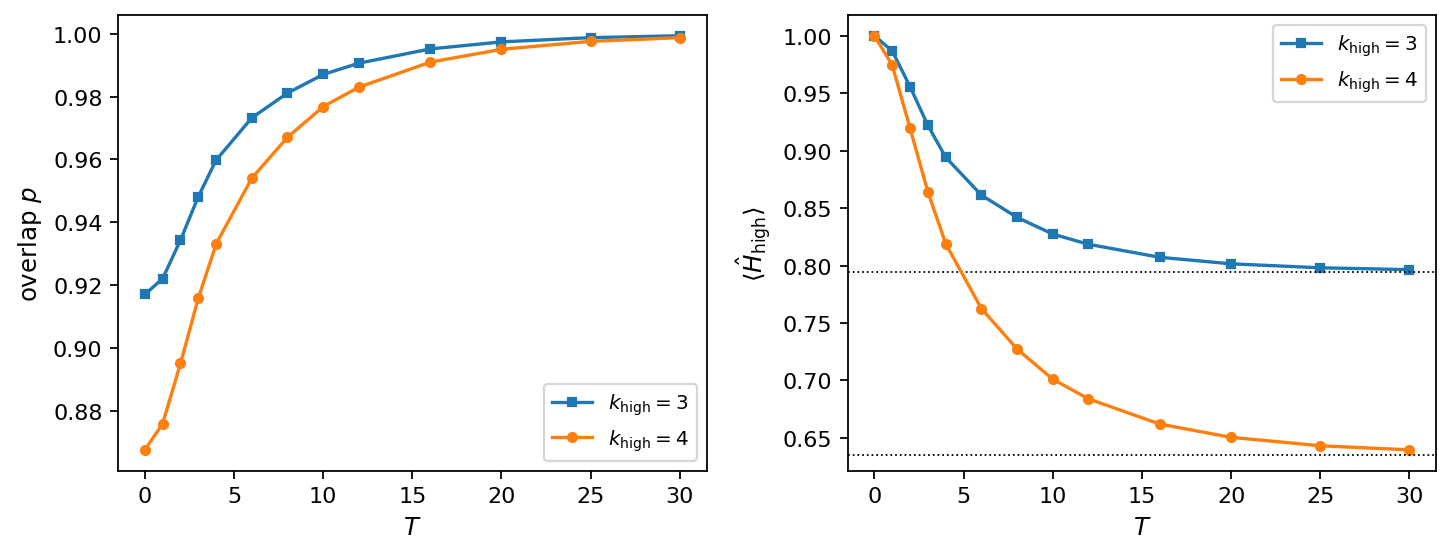

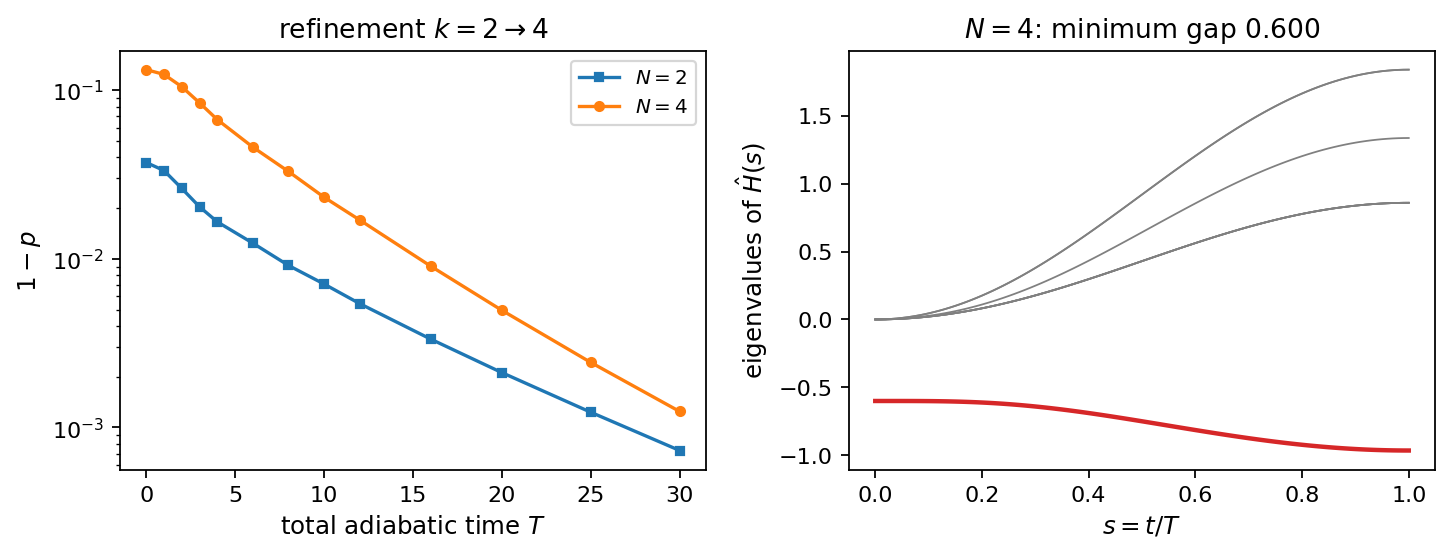

In [4]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter8/refinement.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter8').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


One-qubit Hamiltonian: E0 = -0.618034, E1 = 1.618034
  excited state, t = 1.7, E = 0.3: P(0) = 0.189561307108,  cos^2 = 0.189561307108
  circuit against filter, 16 x 16 random H: |dpsi| = 2.3e-16, |dP| = 3.3e-16
  Gaussian average of cos^2(x t/2), x = E1 - E0: sampled 0.5012, formula 0.5000


  input |+>: weights 0.7236 (ground) and 0.2764; peak heights -> the weights as M grows
    M =  1: P(E0) = 0.8618, P(E1) = 0.6382, background 2^-M = 0.5000
    M =  3: P(E0) = 0.7582, P(E1) = 0.3668, background 2^-M = 0.1250
    M =  6: P(E0) = 0.7279, P(E1) = 0.2877, background 2^-M = 0.0156
    M = 10: P(E0) = 0.7239, P(E1) = 0.2771, background 2^-M = 0.0010



   M   infidelity (sampled, exact average, bound)      acceptance (sampled, exact)
   1   1.580e-01   1.604e-01   1.910e-01        0.8594   0.8618
   2   8.705e-02   8.717e-02   9.549e-02        0.7926   0.7927
   3   4.332e-02   4.557e-02   4.775e-02        0.7564   0.7582
   4   2.186e-02   2.332e-02   2.387e-02        0.7398   0.7409
   5   1.200e-02   1.180e-02   1.194e-02        0.7324   0.7322
   6   6.724e-03   5.933e-03   5.968e-03        0.7285   0.7279
   7   3.551e-03   2.975e-03   2.984e-03        0.7262   0.7258
   8   1.733e-03   1.490e-03   1.492e-03        0.7249   0.7247
   9   8.497e-04   7.455e-04   7.460e-04        0.7242   0.7241
  10   4.594e-04   3.729e-04   3.730e-04        0.7239   0.7239

Sampled runs at E = E0 (M = 6): ancilla record, fidelity with the ground state
  000000  accepted  F = 0.991400
  000000  accepted  F = 0.999253
  000000  accepted  F = 1.000000
  000000  accepted  F = 0.999998
  000000  accepted  F = 0.995948
  001000  rejected  F = 0.00000

  accepted fraction over 4000 runs: 0.730  (Eq. 8.PM: 0.728; p = 0.724)


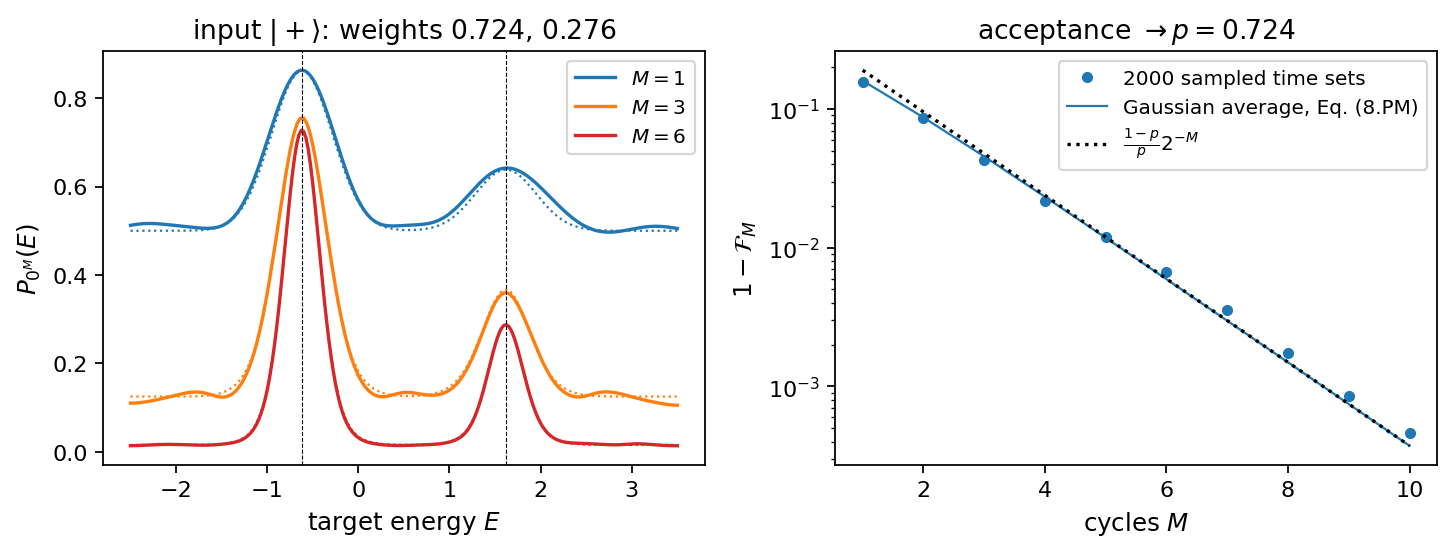

In [5]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter8/rodeo.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter8').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


k = 3: 8 operators (4 singles); analytic against numerical gradient: 2.3e-10

Ground-state energies, N = 4, g = 1
  k  qubits  dim    FCI        CCD        UCCSD      UCCSD-FCI   CCD-FCI   #par  max|singles|   s
  2     4      1  1.000000  1.000000  1.000000  +0.00e+00  +0.00e+00     0  0.0e+00    0.0
  3     6     15  0.794697  0.794697  0.794697  -2.22e-16  +1.40e-13     8  0.0e+00    0.0
  4     8     70  0.635548  0.630443  0.636987  +1.44e-03  -5.11e-03    26  0.0e+00    0.0


  5    10    210  0.497768  0.484977  0.501278  +3.51e-03  -1.28e-02    54  0.0e+00    0.1


  6    12    495  0.372664  0.350058  0.378719  +6.06e-03  -2.26e-02    92  0.0e+00    0.4


  7    14   1001  0.256052  0.221608  0.265052  +9.00e-03  -3.44e-02   140  0.0e+00    0.9


  8    16   1820  0.145559  0.097263  0.157856  +1.23e-02  -4.83e-02   198  0.0e+00    2.2


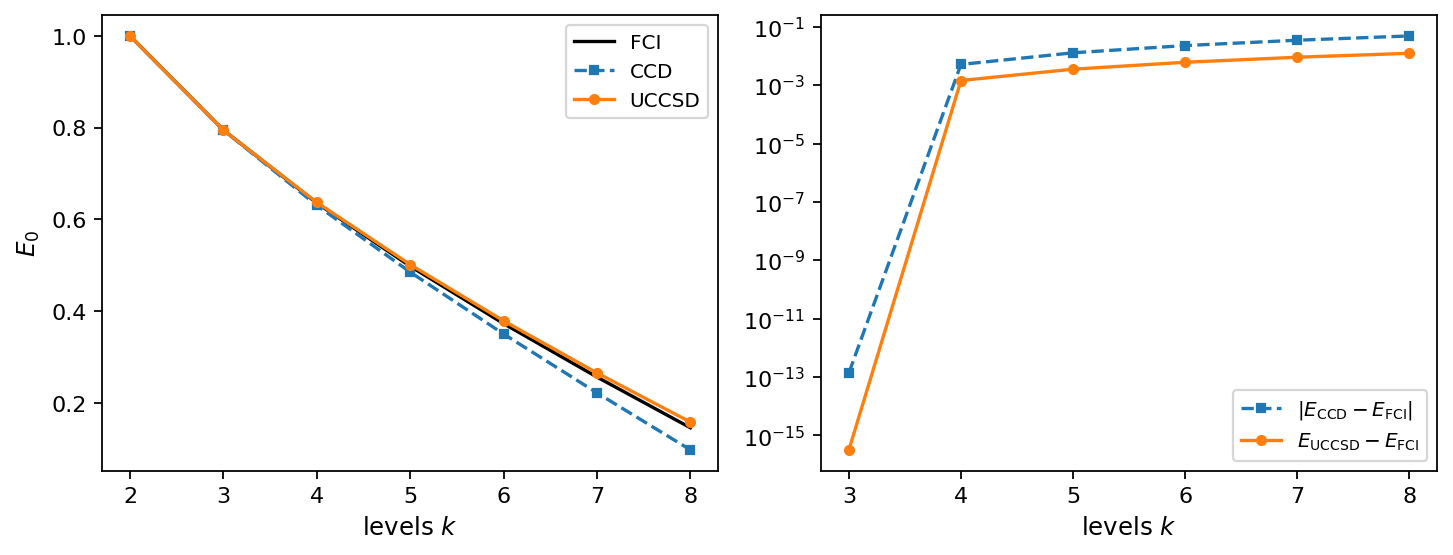

In [6]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter8/uccsd_sector.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter8').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Refinement chains to k = 4 (N = 4, g = 1)


  2 -> 4: E_low = 1.000000, prolonged overlap = 0.8676, T* = 16, min gap = 0.600


  3 -> 4: E_low = 0.794697 (UCCSD), prolonged overlap = 0.9637, T* = 8, min gap = 0.600



Coupling scan, k = 2 -> 4, buffer 0.6
     g    p(0)    min gap    T*(0.99)


   0.3   0.9895   0.6000    1


...


Rodeo inputs: refined p = 0.9988, prolonged p = 0.8676; E0 = 0.635548, first excited state with weight: see scan


  eigenstates carrying weight in the prolonged state: 0.636 (0.8676), 2.935 (0.1063), 5.000 (0.0238), 7.209 (0.0015), 9.220 (0.0007)


  fine scan (sigma = 8, M = 4): peak at E = 0.6355 (grid maximum 0.6355), exact 0.635548

Rodeo preparation at E = E0, sigma = 4: infidelity of the accepted runs and acceptance
   M    refined: infid.   bound      accept.     prolonged: infid.   bound      accept.


   1    6.22e-04   6.22e-04   0.9994      7.09e-02   7.63e-02   0.9338
   2    3.11e-04   3.11e-04   0.9991      3.67e-02   3.81e-02   0.9007
   3    1.56e-04   1.56e-04   0.9989      1.87e-02   1.91e-02   0.8842
   4    7.78e-05   7.78e-05   0.9988      9.44e-03   9.53e-03   0.8759
   5    3.89e-05   3.89e-05   0.9988      4.74e-03   4.77e-03   0.8718
   6    1.94e-05   1.94e-05   0.9988      2.38e-03   2.38e-03   0.8697
   7    9.72e-06   9.72e-06   0.9988      1.19e-03   1.19e-03   0.8687
   8    4.86e-06   4.86e-06   0.9988      5.96e-04   5.96e-04   0.8682



Three cycles with t_j = pi/(E_j - E0) for the three excited levels that carry the most weight
  refined    E_j = 2.9354  weight 7.51e-04  t = 1.3660  infidelity 4.31e-04  acceptance 0.9992
  refined    E_j = 5.0000  weight 4.14e-04  t = 0.7198  infidelity 2.60e-05  acceptance 0.9988
  refined    E_j = 7.2089  weight 4.80e-05  t = 0.4779  infidelity 5.30e-06  acceptance 0.9988
  prolonged  E_j = 2.9354  weight 1.06e-01  t = 1.3660  infidelity 2.67e-02  acceptance 0.8915
  prolonged  E_j = 5.0000  weight 2.38e-02  t = 0.7198  infidelity 6.94e-04  acceptance 0.8682
  prolonged  E_j = 7.2089  weight 1.55e-03  t = 0.4779  infidelity 1.39e-04  acceptance 0.8678


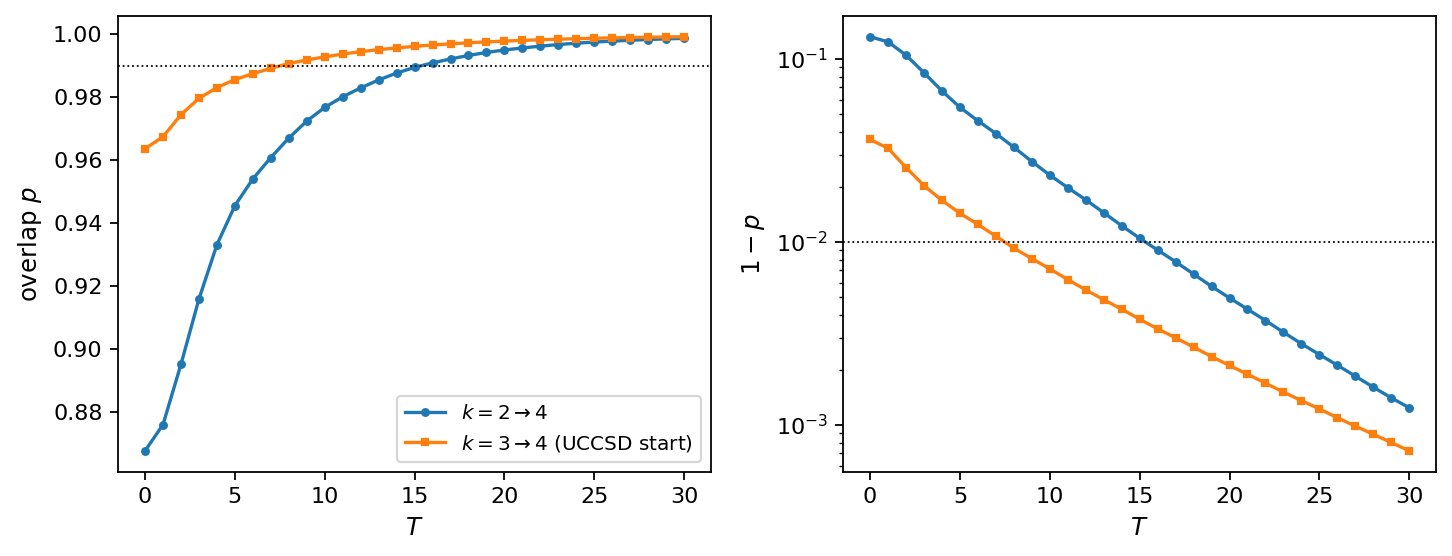

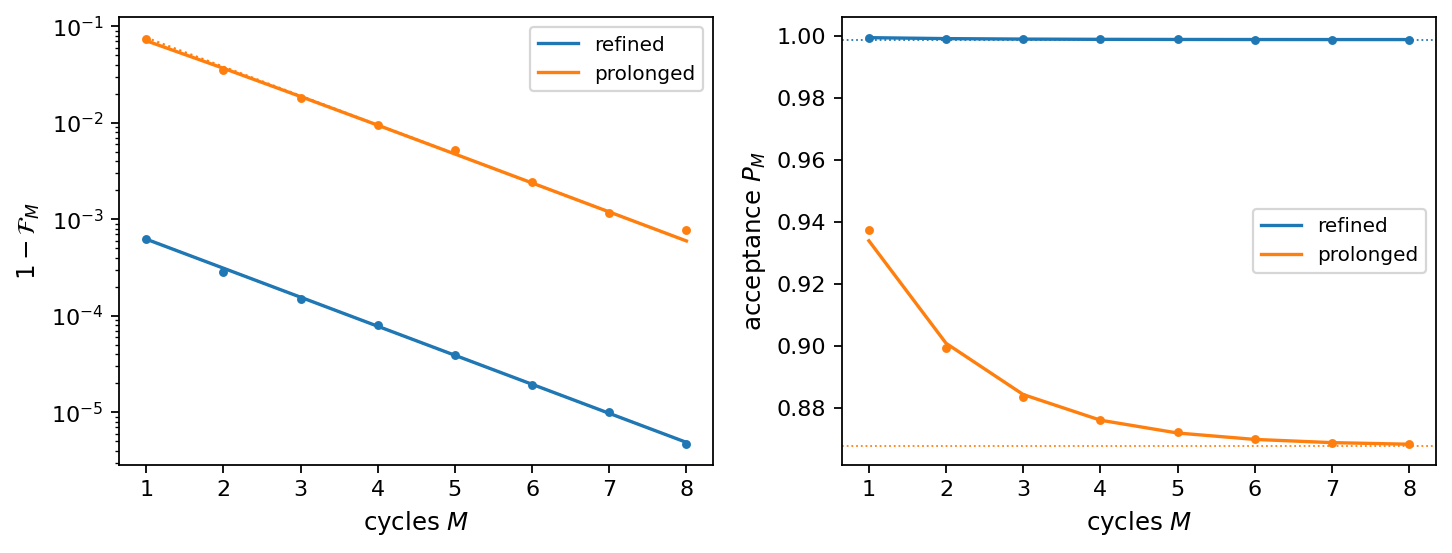

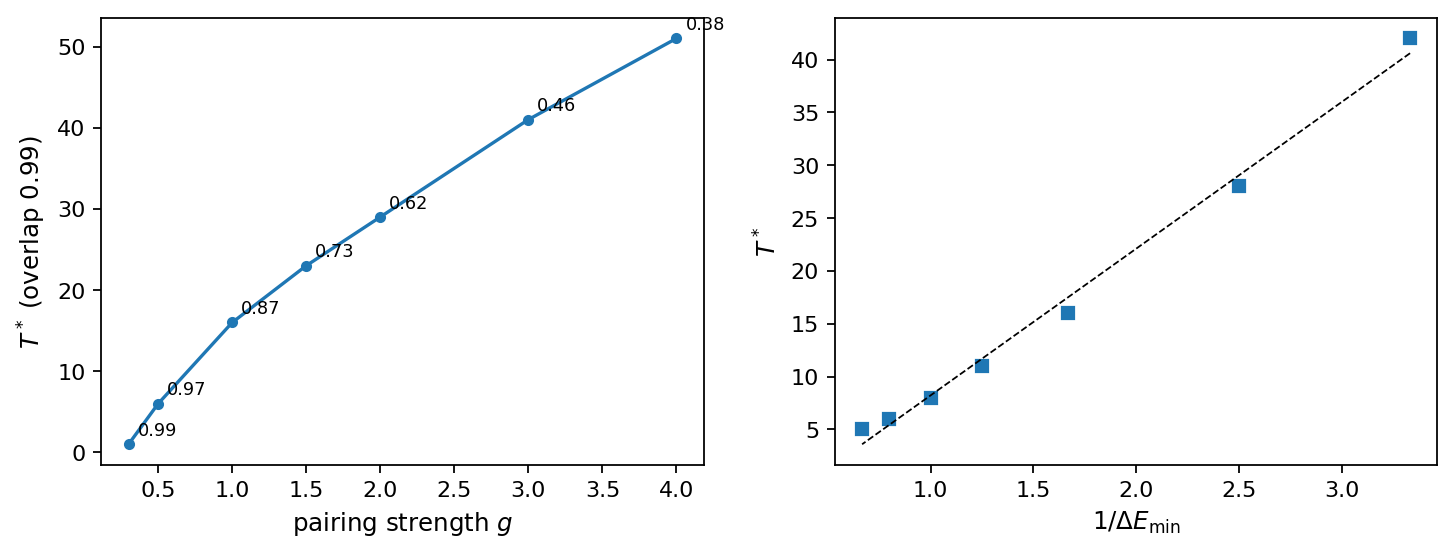

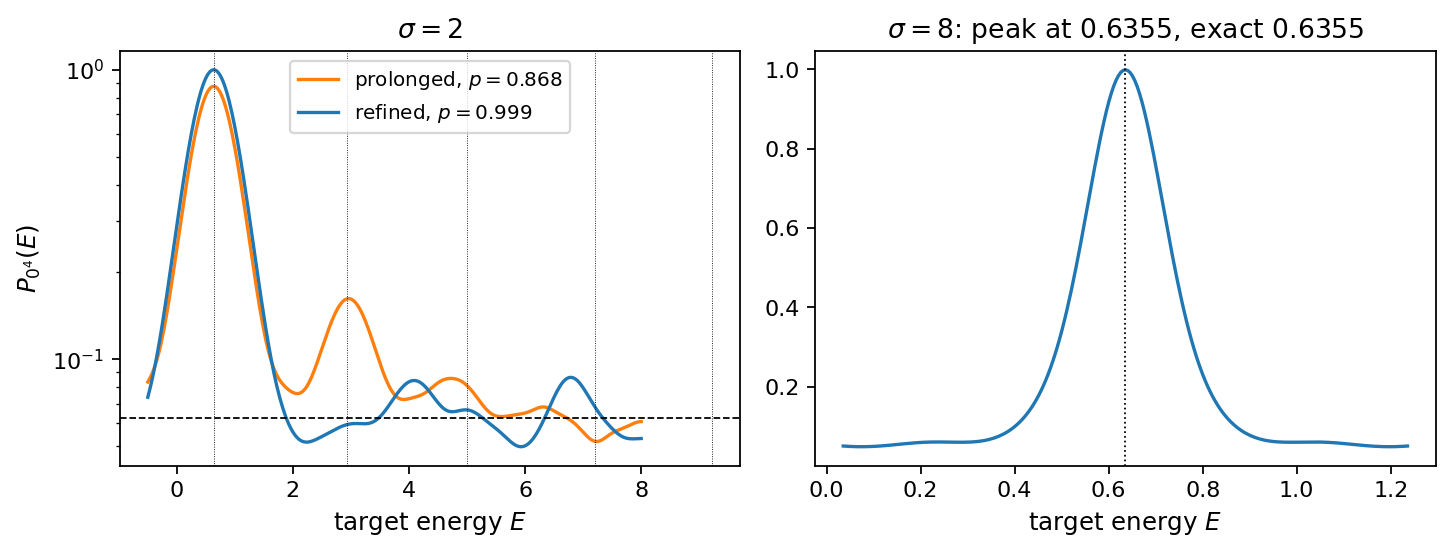

In [7]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter8/pairing_pipeline.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter8').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Sector spectrum from 0.6355 to 9.2201; time step t = 0.6587

Input: prolonged state, p = 0.8676
   phase estimation                                        rodeo, sigma = 4
    m   total time   infidelity   acceptance   E - E0         M   total time   infidelity   acceptance
    2         2.0    4.16e-03     0.7688     +9.1e+00       1         3.2    7.09e-02     0.9338
    3         4.6    4.69e-03     0.5034     +9.1e+00       2         6.4    3.67e-02     0.9007
    4         9.9    1.01e-03     0.7605     +1.2e-01       3         9.6    1.87e-02     0.8842
    5        20.4    3.74e-04     0.4974     +1.2e-01       4        12.8    9.44e-03     0.8759
    6        41.5    6.86e-05     0.7594     -3.0e-02       5        16.0    4.74e-03     0.8718
    7        83.7    1.57e-05     0.4970     -3.0e-02       6        19.1    2.38e-03     0.8697
    8       168.0    4.61e-06     0.7593     +7.5e-03       7        22.3    1.19e-03     0.8687
    9       336.6    1.35e-07     0.4970     +


UCCSD at k = 4: E - E_FCI = 1.44e-03, infidelity 1 - p = 1.78e-04
   rodeo cycles on the UCCSD state:  M   infidelity   acceptance   energy error of the filtered state
                                     1   8.88e-05     0.9999       7.19e-04
                                     2   4.44e-05     0.9999       3.60e-04
                                     4   1.11e-05     0.9998       8.99e-05
                                     6   2.78e-06     0.9998       2.25e-05


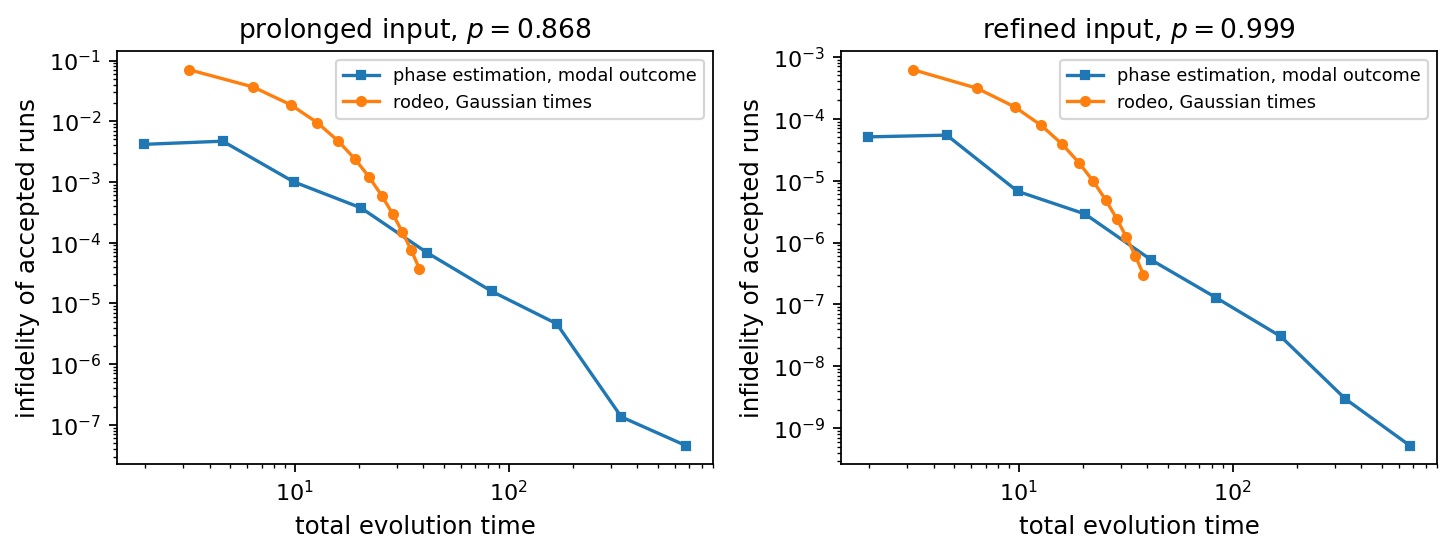

In [8]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter8/filters_compared.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter8').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Refinement, buffer = 1.0
   case                  dim    E_high      <H>_prol    p(0)     min gap   T*(0.99)   p(10)    p(20)


   Lipkin N=2->4          16    -4.21288    -4.02759   0.9458   1.0000       6      0.9978   0.9998


   Lipkin, V=-1           16    -5.53585    -4.23607   0.7506   0.9995      14      0.9789   0.9981
   Heisenberg 2->4         6    -2.00000    -1.50000   0.7500   0.9082      10      0.9932   0.9999


   Heisenberg 4->8        70    -3.65109    -3.00000   0.5043   0.5223      14      0.9541   0.9981


   Hubbard 2->4           70    -2.10275    -0.00000   0.4249   0.2963      18      0.9183   0.9955

Heisenberg 2 -> 4: overlap of the prolonged state with the ground state, Marshall sign 0.7500, plus sign 0.0833

Rodeo at E = E_0, sigma = 4: infidelity of the accepted runs (exact Gaussian average)
   case                  input       p        M = 2      M = 4      M = 8      acceptance (M = 8)
   Lipkin N=2->4        prolonged  0.9458   1.41e-02   3.57e-03   2.24e-04   0.9461
   Lipkin N=2->4        refined    0.9998   4.43e-05   1.11e-05   6.92e-07   0.9998
   Lipkin, V=-1         prolonged  0.7506   7.67e-02   2.03e-02   1.30e-03   0.7516
   Lipkin, V=-1         refined    0.9981   4.79e-04   1.20e-04   7.49e-06   0.9981
   Heisenberg 2->4      prolonged  0.7500   7.69e-02   2.04e-02   1.30e-03   0.7510
   Heisenberg 2->4      refined    0.9999   2.00e-05   5.00e-06   3.13e-07   0.9999
   Heisenberg 4->8      prolonged  0.5043   1.97e-01   5.80e-02   3.84e-03   0.5062
   Heisenberg 


Hubbard ring: levels carrying weight in the prolonged state: -2.103 (0.425), -1.068 (0.276), 2.965 (0.205), 5.035 (0.071), 10.103 (0.018)

Two particles on an open chain, t -> 4t, U -> 2U per stage, buffer 4 (scaled), T = 2 (scaled)
   stage    dim   E_low      <H>_prol    E_high     p(0)     p(T)     rodeo M = 4


   2 -> 4     28     2.7639     4.9751     4.0506   0.9093   0.9949   3.2e-04
   4 -> 8    120     4.1081     7.3621     4.9946   0.9424   0.9849   9.6e-04


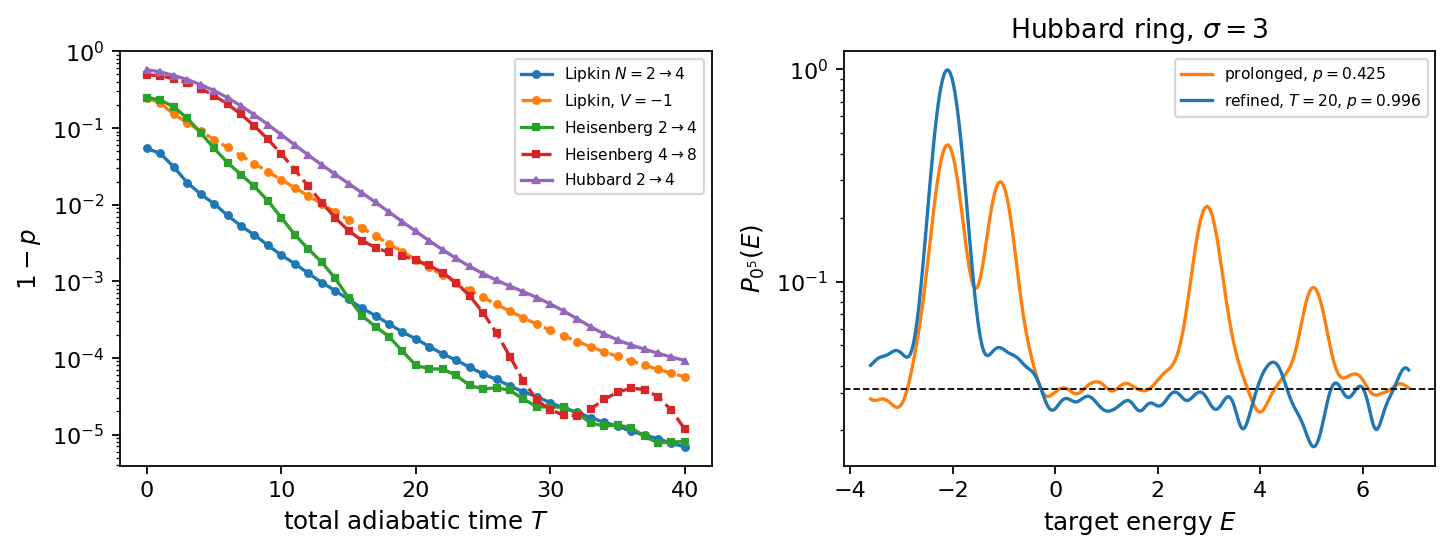

In [9]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter8/other_models.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter8').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


Spectral-norm error of the product formula for exp(-iH), t = 1 (k = 4, N = 4, g = 1)
  steps   first order   second order
     1    1.50e+00      9.63e-01
     2    6.47e-01      1.49e-01
     4    3.07e-01      3.40e-02
     8    1.51e-01      8.32e-03
    16    7.48e-02      2.07e-03

Trotterised refinement k = 2 -> 4, T = 30: exact slices give p = 0.9988
   n_s   first order   second order
    20    0.1672        0.0125


    40    0.6435        0.9436
    80    0.9386        0.9977


   160    0.9815        0.9986


   320    0.9931        0.9987


   640    0.9967        0.9987

Rodeo on the n_s = 80 second-order refined state (p = 0.9977), sigma = 4.0, mean steps per cycle = sigma sqrt(2/pi)/dt
    dt     steps/cycle   infidelity M = 2   M = 6     acceptance M = 6
   exact        -        5.71e-04         3.57e-05   0.9978


   1.000        3.2      9.60e-02         1.40e-01   0.0777


   0.500        6.4      2.08e-03         1.90e-03   0.8140


   0.250       12.8      6.39e-04         1.43e-04   0.9859


   0.125       25.5      5.50e-04         3.88e-05   0.9971



Ground state of the effective Hamiltonian of one second-order step against the true one
   dt = 1.000: 1 - |<E0|E0_eff>|^2 = 3.13e-01, E0_eff - E0 = +6.55e-01
   dt = 0.500: 1 - |<E0|E0_eff>|^2 = 3.09e-03, E0_eff - E0 = +1.05e-01
   dt = 0.250: 1 - |<E0|E0_eff>|^2 = 1.48e-04, E0_eff - E0 = +2.45e-02
   dt = 0.125: 1 - |<E0|E0_eff>|^2 = 8.73e-06, E0_eff - E0 = +6.03e-03


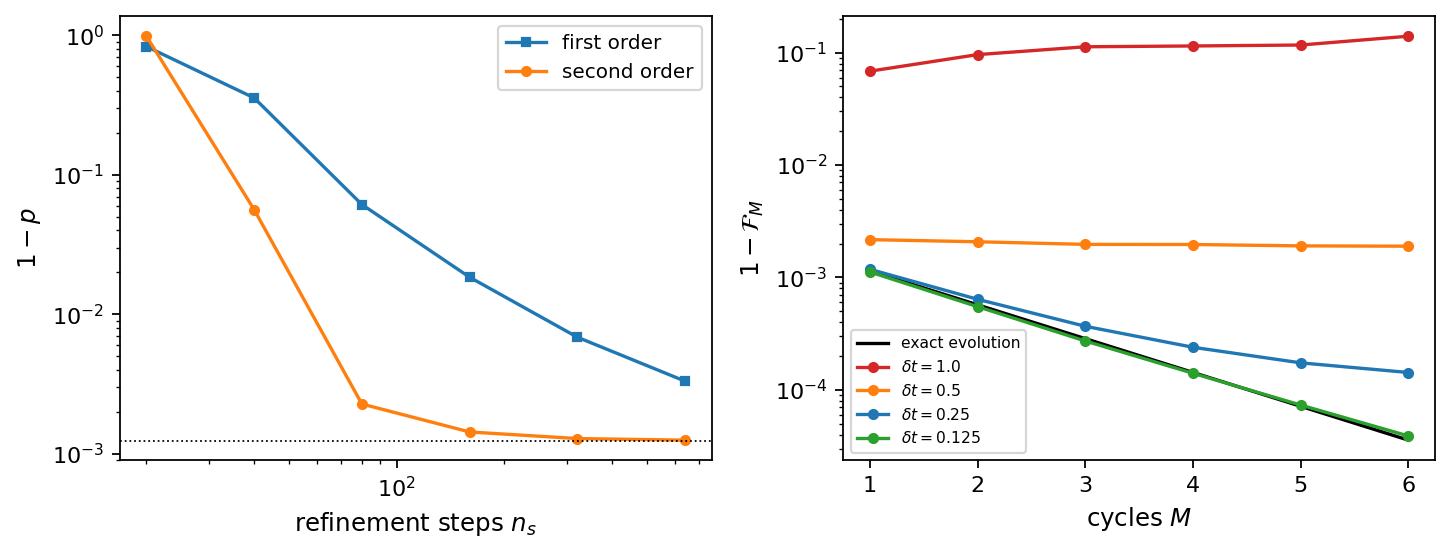

In [10]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter8/trotter_pipeline.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter8').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


In [11]:
import runpy, time
from IPython.display import Image, display
t0 = time.time()
runpy.run_path(str(root / 'BookPrograms' / 'chapter8/gate_budget.py'), run_name='__main__')
for png in sorted((root / 'BookFigures' / 'chapter8').glob('*.png')):
    if png.stat().st_mtime >= t0:
        display(Image(str(png)))


exp(-i phi/2 XXXY): 17 gates, 6 CNOTs, depth 9, error 6.5e-16

Jordan-Wigner strings of tau - tau^dagger (k = 3, six qubits)
  single 0 -> 4            2 strings, weights [(5, 2)], 16 CNOTs
  single 1 -> 5            2 strings, weights [(5, 2)], 16 CNOTs
  single 2 -> 4            2 strings, weights [(3, 2)], 8 CNOTs
  pair (2,3) -> (4,5)      8 strings, weights [(4, 8)], 48 CNOTs
  pair (0,1) -> (4,5)      8 strings, weights [(4, 8)], 48 CNOTs
  double (0,3) -> (4,5)    8 strings, weights [(6, 8)], 80 CNOTs

UCCSD preparation, N = 4
  k   operators  rotations  CNOTs    pair doubles only: operators  CNOTs
  3        8         40      272                              2       96
  4       26        160     1312                              4      192

One first-order Trotter step of the pairing Hamiltonian: CNOTs plain / controlled
   k   Jordan-Wigner, 2k qubits      formula 24k(k-1)+2k     compact, k qubits
   2        52 /    80                 52                   4 /   12     string

   Lipkin, N=4           4      16      24       56
   pairing, L=4          4      16      24       56
   Hubbard ring          8      28      56      112
   Heisenberg ring       4      12      24       48

Expected faults N eps and success probability exp(-N eps)
   circuit                     CNOTs   eps=1e-02   eps=1e-03   eps=1e-04   eps=1e-06
   UCCSD, k = 3                   272    6.59e-02    7.62e-01    9.73e-01    1.00e+00
   UCCSD, k = 4                  1312    2.00e-06    2.69e-01    8.77e-01    9.99e-01
   pipeline, compact, M = 2      6223    9.38e-28    1.98e-03    5.37e-01    9.94e-01
   pipeline, JW, M = 2          65100   1.89e-283    5.34e-29    1.49e-03    9.37e-01
